In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
# sys.path.append('../')
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

from matplotlib import pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path

sys.path.append('/global/cfs/cdirs/alice/heppy_soft/05-11-2023/yasp/software/root/6.28.00/lib')
import ROOT

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black', 'gold', 'hotpink']
# L_colors = ['hotpink', 'red', 'darkorange', 'gold', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P', "X", "*", "o", '8']
# L_markers = ['s', 'p', '^', 'v', 'd', 'P', "X", "*", '8']

Welcome to JupyROOT 6.28/06


In [2]:
'''
def get_lin_bincenters(bin_edges):
    """
    Calculates the midpoints (centers) of linear bins from an array of bin edges.
    """
    return (bin_edges[:-1] + bin_edges[1:]) / 2.0

def get_log_bincenters(bin_edges):
    """
    Calculates the geometric midpoints (log centers) of bins from an array of bin edges.
    """
    # Standard formula using the geometric mean (square root of the product of edges)
    return np.sqrt(bin_edges[:-1] * bin_edges[1:])

def get_binwidths(bin_edges):
    """
    Calculates the width of each bin from an array of bin edges.
    """
    return np.diff(bin_edges)

def safe_divide(numerator, denominator, filler=0.0):
    """
    Safely divides two arrays element-wise. Replaces division-by-zero 
    and NaN results with the specified filler value.
    """
    # Convert inputs to numpy arrays just in case they are passed as lists
    num = np.asarray(numerator, dtype=float)
    den = np.asarray(denominator, dtype=float)
    
    # Use np.divide's 'where' parameter to only divide where denominator is non-zero
    # Out determines what to place where the condition is False
    result = np.divide(num, den, out=np.full_like(num, filler), where=(den != 0.0))
    
    # Final safety sweep to catch any unexpected NaNs or Inf values
    result = np.nan_to_num(result, nan=filler, posinf=filler, neginf=filler)
    
    return result
'''

'\ndef get_lin_bincenters(bin_edges):\n    """\n    Calculates the midpoints (centers) of linear bins from an array of bin edges.\n    """\n    return (bin_edges[:-1] + bin_edges[1:]) / 2.0\n\ndef get_log_bincenters(bin_edges):\n    """\n    Calculates the geometric midpoints (log centers) of bins from an array of bin edges.\n    """\n    # Standard formula using the geometric mean (square root of the product of edges)\n    return np.sqrt(bin_edges[:-1] * bin_edges[1:])\n\ndef get_binwidths(bin_edges):\n    """\n    Calculates the width of each bin from an array of bin edges.\n    """\n    return np.diff(bin_edges)\n\ndef safe_divide(numerator, denominator, filler=0.0):\n    """\n    Safely divides two arrays element-wise. Replaces division-by-zero \n    and NaN results with the specified filler value.\n    """\n    # Convert inputs to numpy arrays just in case they are passed as lists\n    num = np.asarray(numerator, dtype=float)\n    den = np.asarray(denominator, dtype=float)\n\n    

In [3]:
# closure test? i.e. there is truth pythia data somewhere to compare to
closure = True

JETPT_BINS = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500], dtype=np.float64)

RL_NBINS = 24 #25
RL_MIN, RL_MAX = 0.01, 1.0
RL_BINS = np.logspace(np.log10(RL_MIN), np.log10(RL_MAX), RL_NBINS + 1)

W_NBINS = 20 #30 #100
W_MIN, W_MAX = 0.0, 0.3 #1.0 #0.3
W_BINS = np.logspace(-5,-0.5,W_NBINS+1)


# define binnings
n_bins_true = [9, 24, 20] # jet pt, RL, weight #[20, 12, 6] # [20, 22, 7]
# RL_bins = np.array([0.00796, 0.01, 0.0144544, 0.020893, 0.0301995, 0.0436516,
#                     0.0630957, 0.0912011, 0.131826, 0.190546, 0.275423, 0.398107, 0.47863])
# # RL_bins = np.logspace(-2, 0, n_bins_true[1]+1)
RL_bins = RL_BINS

# binning = [np.logspace(-5,-0.5,n_bins_true[0]+1), \
#             RL_bins, \
#             # np.logspace(-2.299,0,n_bins_true[1]+1), \ 
#             np.array([10, 20, 40, 60, 80, 100, 150]).astype(float) ]
#             # np.array([5, 10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning = [JETPT_BINS, \
           RL_bins, \
           W_BINS ]
print(binning)
# bincenters = [ get_log_bincenters(binning[0]), get_log_bincenters(binning[1]), get_lin_bincenters(binning[2]) ]
bincenters = [ get_lin_bincenters(binning[0]), get_log_bincenters(binning[1]), get_log_bincenters(binning[2]) ]
binwidths = [ np.array(get_binwidths(a)) for a in binning ]
print(binwidths)

n_bins = [9, 24, 20] #[20, 12, 6] # [20, 22, 6] # WARNING RooUnfold seg faults if too many bins used
# binning_reco = [np.logspace(-5,-0.5,n_bins[0]+1), \
#             RL_bins, \
#             # np.logspace(-2.299,0,n_bins[1]+1), \
#             np.array([10, 20, 40, 60, 80, 100, 150]).astype(float) ]
binning_reco = [JETPT_BINS, \
                RL_bins, \
                W_BINS ]
# bincenters_reco = [ get_log_bincenters(binning_reco[0]), get_log_bincenters(binning_reco[1]), get_lin_bincenters(binning_reco[2]) ]
bincenters_reco = [ get_lin_bincenters(binning_reco[0]), get_log_bincenters(binning_reco[1]), get_log_bincenters(binning_reco[2]) ]
binwidths_reco = [ np.array(get_binwidths(a)) for a in binning_reco ]

labels = ["jet $p_T$", "$R_L$", "energy weight"] #["energy weight", "$R_L$", ""]

n_iter = 5

[array([ 10.,  20.,  40.,  60.,  80., 100., 120., 150., 200., 500.]), array([0.01      , 0.01211528, 0.01467799, 0.01778279, 0.02154435,
       0.02610157, 0.03162278, 0.03831187, 0.04641589, 0.05623413,
       0.06812921, 0.08254042, 0.1       , 0.12115277, 0.14677993,
       0.17782794, 0.21544347, 0.26101572, 0.31622777, 0.38311868,
       0.46415888, 0.56234133, 0.68129207, 0.82540419, 1.        ]), array([1.00000000e-05, 1.67880402e-05, 2.81838293e-05, 4.73151259e-05,
       7.94328235e-05, 1.33352143e-04, 2.23872114e-04, 3.75837404e-04,
       6.30957344e-04, 1.05925373e-03, 1.77827941e-03, 2.98538262e-03,
       5.01187234e-03, 8.41395142e-03, 1.41253754e-02, 2.37137371e-02,
       3.98107171e-02, 6.68343918e-02, 1.12201845e-01, 1.88364909e-01,
       3.16227766e-01])]
[array([ 10.,  20.,  20.,  20.,  20.,  20.,  30.,  50., 300.]), array([0.00211528, 0.00256272, 0.0031048 , 0.00376155, 0.00455723,
       0.0055212 , 0.00668909, 0.00810402, 0.00981824, 0.01189507,
       0.014411

In [4]:
# file defs, hist imports

f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/60403841/response_groomed_forunfolding_merged.root")
f_preunfold_data = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/data/60320414/AnalysisResultsMerged_groomedbins.root")
f_unfolded1D = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D.root")
f_unfolded = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded.root")

# const TString& outfile="/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D_tests.root",


# DEFINE FUNCTIONS

In [5]:
# Does "unmatched" == "all"???? in the MC files?

def get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm): #, f_prefundold_gen):
    # Data, reco [theta_unknown_S]
    h3_raw = f_preunfold_data["{}_sd0.1_raw".format(lab)]
    h1_raw = f_preunfold_data["groomed_sd0.1_jet_pt_raw1D"]

    # MC, reco [theta0_S]
    h3_reco = f_preunfold_rm["groomed_{}_reco_matched".format(lab)]
    h1_reco = f_preunfold_rm["jet_match_rec_pur_num_groomed"] #reco1D"]

    # MC, true [theta0_G]
    h3_gen = f_preunfold_rm["groomed_{}_gen_matched".format(lab)] #TODO: get this added
    h1_gen = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #gen1D"]

    # Data, true [theta_unknown_G]
    # NO TRUE DATA HERE

    h3_unfolded = []
    #h1_unfolded = [] TODO add in h1 unfolded support
    for i in range(1,n_iter+1):
        h3_unfolded.append(f_unfolded["Bayesian_Unfolded_{}_iter{}".format(lab, i)])

    h3_raw_purity = f_unfolded["{}_raw_corrected".format(lab)] #"raw{}".format(bkg)] # TODO: is this right??

    return h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity


In [6]:
def FindBin(binx, biny, binz):
    assert binx < n_bins[0] and biny < n_bins [1] and binz < n_bins[2] \
            and 0 <= binx and 0 <= biny and 0 <= binz
    return binx + n_bins[0]*(biny + n_bins[1]*binz)

def FindIndex(bin_n):
    binz = bin_n // (n_bins_true[0] * n_bins_true[1])
    bin_n -= binz * (n_bins_true[0] * n_bins_true[1])

    biny = bin_n // n_bins_true[0]
    binx = bin_n % n_bins_true[0]

    return binx, biny, binz
    
def get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true):
    matrix = f_unfolded["matrix_{}".format(lab)].values()
    matrix1D = f_unfolded1D["matrix1D"].values()
    print(matrix1D)

    [matrixx, matrixy, matrixz] = [np.zeros((n_bins[i], n_bins_true[i])) for i in range(3)]

    N = n_bins_true[0]*n_bins_true[1]*n_bins_true[2]

    print(N)

    for i in range(n_bins[0]):
        for j in range(n_bins[1]):
            for k in range(n_bins[2]):

                reco_bin = FindBin(i, j, k)
                for m in range(N):
                    
                    binx, biny, binz = FindIndex(m)
                    bincontent = matrix[reco_bin][m]

                    matrixx[i][binx] += bincontent
                    matrixy[j][biny] += bincontent
                    matrixz[k][binz] += bincontent

    matricies = [matrixx, matrixy, matrixz]

    return matrix1D, matricies


In [7]:
# print response matricies

def print_response_matricies(matrix1D, matricies, binning_reco, binning, labels):
    # Create subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for i in range(3):
        ax = axes[i]

        # Plot histograms
        #ax.imshow(matrix.values(), origin='lower', extent=[binning[0][0], binning[0][-1], binning[0][0], binning[0][-1]], cmap='viridis')
        h = matricies[i]
        print(h.shape)
        print(len(binning_reco[0])) #len(binning_reco[2]))
        print(len(binning[0])) #len(binning[2]))
        plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')
        ax.set_title(labels[i])
        ax.set_xlabel('reco')
        ax.set_ylabel('true')

        if i in [1,2]:
            ax.set_xscale('log')
            ax.set_yscale('log')

        fig.colorbar(plot)

    # Show plot
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 1, figsize=(6, 5))

    ax = axes
    h = matrix1D
    plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')
    ax.set_title(labels[0]) #(labels[2])
    ax.set_xlabel('reco')
    ax.set_ylabel('true')

    fig.colorbar(plot)

    # Show plot
    plt.tight_layout()
    plt.show()


In [8]:
# get projections
def get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded):
    proj = lambda a : [projectionX(a.values()), projectionY(a.values()), projectionZ(a.values())]
    proj_err = lambda a : [projectionX(a.errors()), projectionY(a.errors()), projectionZ(a.errors())]

    theta0_G = proj(h3_gen)
    theta0_S = proj(h3_reco)
    theta_unknown_S = proj(h3_raw)

    theta_unfolded = [proj(a) for a in h3_unfolded]

    theta0_G_err = proj_err(h3_gen)
    theta0_S_err = proj_err(h3_reco)
    theta_unknown_S_err = proj_err(h3_raw)

    theta_unfolded_err = [proj_err(a) for a in h3_unfolded]

    matrixify = lambda A : projectionZY(A.values()).T #projectionXY(A.values()).T
    matrixify_err = lambda A: projectionZY(A.errors()).T #projectionXY(A.errors()).T

    U_unfolded = [matrixify(A) for A in h3_unfolded]
    U_unfolded_err = [matrixify_err(A) for A in h3_unfolded]

    # theta0_G = proj(theta_unknown_S * h3_raw_purity.values())

    print(theta0_G)

    return theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err


In [9]:
############################## UNFOLDED DISTRIBUTIONS ############################
# individual distros

def plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                           theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err):
    it = 5

    fig, axes = plt.subplots(3, 3, figsize=(15,12))

    # ROW 1: raw distributions
    for i in range(3):
        ax = axes[0, i]

        #ax.plot(bincenters_reco[i], theta_unknown_S[i], color='black', linestyle='dashed', alpha=0.6, label="data, raw")

        for iteration in range(it):
            ax.scatter(bincenters[i], theta_unfolded[iteration][i],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
            ax.set_ylabel("Counts")

            ax.errorbar(bincenters[i], theta_unfolded[iteration][i], yerr=theta_unfolded_err[iteration][i], capsize=5, capthick=2, fmt='o', linestyle="None", color=L_colors[iteration])
            
            ax.set_title(labels[i])
            ax.set_xlabel(labels[i])
            
            ax.legend(frameon=False)

            if i in [1, 2]:
                ax.set_xscale('log')
            ax.set_yscale('log')
            ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])

        ax.scatter(bincenters[i], theta0_G[i],color='blue',marker='o',label="gen",lw=1)
        ax.errorbar(bincenters[i], theta0_G[i], yerr=theta0_G_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='blue')
        ax.scatter(bincenters[i], theta0_S[i],color='gold',marker='o',label="det",lw=1)
        ax.errorbar(bincenters[i], theta0_S[i], yerr=theta0_S_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='gold')
        ax.scatter(bincenters[i], theta_unknown_S[i],color='hotpink',marker='o',label="data",lw=1)
        ax.errorbar(bincenters[i], theta_unknown_S[i], yerr=theta_unknown_S_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='hotpink')
        
        ax.legend(frameon=False)

        # if i in [1, 2]:
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])

        if i == 0:
            info_text = (f"{lab} pairs\njet p_{{T}} = 10-500 GeV/c") #\n")
            ax.text(0.4, 0.15,  info_text, transform=ax.transAxes,  fontsize=10, verticalalignment="top", horizontalalignment="left")


    # ROW 2: convergence plot (n / n - 1)
    for i in range(3):
        ax = axes[1, i]

        for iteration in range(1,it):
        
            yvals = safe_divide(theta_unfolded[iteration][i] , theta_unfolded[iteration-1][i], filler=1)
            ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

            ax.hlines(y=1, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

            ax.set_title(labels[i])
            ax.set_xlabel(labels[i])
            ax.set_ylabel("n / (n-1)")
            ax.legend(frameon=False)

            # if i in [1, 2]:
            ax.set_xscale('log')
            ax.set_ylim([0.9, 1.1])
            ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


    # ROW 3: statistical error %
    for i in range(3):
        ax = axes[2, i]

        for iteration in range(it):
            
            yvals = safe_divide(theta_unfolded_err[iteration][i], theta_unfolded[iteration][i])
            print(theta_unfolded_err[iteration][i])
            print(theta_unfolded[iteration][i])
            print()
            ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

            ax.set_title(labels[i])
            ax.set_xlabel(labels[i])
            ax.set_ylabel("unfolding uncertainty")
            ax.legend(frameon=False)

            # if i in [1, 2]:
            ax.set_xscale('log')
            ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


    fig.tight_layout()
    plt.show()

In [10]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros - weighted (not normalized or divided into pt bins)

def plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning):
    it = 5

    fig, axes = plt.subplots(1, 3, figsize=(15,4))

    # EEC weight calculation:
    # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

    unfolded_EEC = np.array([[np.dot(col, bincenters[2]) for col in U_unfolded[iteration]] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[2])**2)) for col in U_unfolded_err[iteration]] for iteration in range(len(theta_unfolded))])

    # TODO propagate error from N_jets here, i dont wanna do ittttt

    # COL 1: raw EEC distribution WITH relative error over data, true underneath
    ax = axes[0]

    rl_lims = ax.set_xlim([8E-3, 1])

    for iteration in range(it):

        ax.scatter(bincenters[1], unfolded_EEC[iteration] / binwidths[1],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("EEC")
        
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])

        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    info_text = (f"{lab} pairs\njet p_{{T}} = 10-500 GeV/c") #\n")
    ax.text(0.5, 0.15,  info_text, transform=ax.transAxes,  fontsize=10, verticalalignment="top", horizontalalignment="left")
    
    
    # COL 2: convergence plot (n / n - 1)
    ax = axes[1]

    for iteration in range(1,it):

        yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_ylim([0.85, 1.15])
        ax.set_xlim(rl_lims)


    # COL 3: statistical error %
    ax = axes[2]

    for iteration in range(it):
        
        yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_xlim(rl_lims)


    fig.tight_layout()
    plt.show()


In [11]:
# Here, i is the iteration number, and the tupes are (jet pt, RL, weight)
def reveal_shape(h3_unfolded):
    for i, item in enumerate(h3_unfolded):
        vals = item.values()
        if hasattr(vals, 'shape'):
            print(f"Element {i} shape:", vals.shape)
        elif isinstance(vals, (list, tuple)):
            print(f"Element {i} length:", len(vals))

In [12]:
############################## R_L REBINNING HELPERS ##############################

def rebin_rl_counts(U, factor=2):
    """Sum adjacent R_L bins (axis 0) of an (n_RL, n_E) array of counts."""
    U = np.asarray(U)
    n_rl = U.shape[0]
    if n_rl % factor != 0:
        raise ValueError(f"Number of R_L bins ({n_rl}) not divisible by rebin factor {factor}")
    return U.reshape(n_rl // factor, factor, *U.shape[1:]).sum(axis=1)

def rebin_rl_errors(E, factor=2):
    """Combine errors of adjacent R_L bins in quadrature (ignores bin-to-bin correlations)."""
    E = np.asarray(E)
    n_rl = E.shape[0]
    if n_rl % factor != 0:
        raise ValueError(f"Number of R_L bins ({n_rl}) not divisible by rebin factor {factor}")
    return np.sqrt((E**2).reshape(n_rl // factor, factor, *E.shape[1:]).sum(axis=1))

def rebin_rl_axis(edges, centers, factor=2):
    """Return merged edges, centers, widths. Keeps the same center convention
    (geometric or arithmetic) as the original binning."""
    edges = np.asarray(edges)
    centers = np.asarray(centers)
    new_edges = edges[::factor]
    new_widths = np.diff(new_edges)
    if np.all(edges > 0) and np.allclose(centers, np.sqrt(edges[:-1] * edges[1:])):
        new_centers = np.sqrt(new_edges[:-1] * new_edges[1:])   # log binning
    else:
        new_centers = 0.5 * (new_edges[:-1] + new_edges[1:])    # linear binning
    return new_edges, new_centers, new_widths


In [13]:
############################## UNFOLDED DISTRIBUTIONS ############################
############################## ( with pT cut applied ) ###########################
# EEC distros - weighted and divided into pt bins and normalized

# what is theta_unfolded? N_jets_unf?
def plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels,
                                rebin_pt_threshold=100, rl_rebin_factor=2,
                                h3_unfolded_rebin=None, rl_rebin_binning=None):
    """
    EEC per jet-pT bin, normalized as (1/N_jets) dSigma/dR_L.

    For pT bins whose lower edge is >= rebin_pt_threshold (100 GeV), the unfolded
    curves are taken from the RL-rebinned unfolding output (unfolded_rebinRL2.root,
    12 R_L bins) when h3_unfolded_rebin is given -- one unfolded TH3 per iteration,
    plus rl_rebin_binning = (edges, centers, widths) of the rebinned R_L axis.
    They are normalized with the same N_jets (from the 1D jet-pT histograms) as the
    fine panels, together with the rebinned R_L bin widths, so all pT panels share
    one normalization convention. Without h3_unfolded_rebin the fine (24-bin)
    histograms are locally rebinned as before.
    """

    # EEC distros

    it = 5
    # j = 0

    for i in range(1, 8):

        fig, axes = plt.subplots(1, 3, figsize=(15, 4))

        # apply pt cut
        ptcut_bins = [i, i+1]
        slice_on_pt = lambda h: xslice_th3d(h, ptcut_bins[0], ptcut_bins[1])
        ptcut_bins_reco = [i, i+1]
        slice_on_pt_reco = lambda h: xslice_th3d(h, ptcut_bins_reco[0], ptcut_bins_reco[1])

        # unfolded source for this panel: the RL-rebinned unfolding file for
        # pT >= 100 GeV, the fine (24-bin) histograms otherwise
        use_rebin_file = (h3_unfolded_rebin is not None
                          and JETPT_BINS[ptcut_bins[0]] >= rebin_pt_threshold)

        if use_rebin_file:
            U_unfolded_cut = [xslice_th3d(A.values(), i, i+1) for A in h3_unfolded_rebin]
            U_unfolded_err_cut = [xslice_th3d(A.errors(), i, i+1) for A in h3_unfolded_rebin]

            # raw data stays on the fine (24-bin) histograms, rebinned locally to match
            U_raw_cut = rebin_rl_counts(slice_on_pt_reco(h3_raw.values()), rl_rebin_factor)
            U_raw_err_cut = rebin_rl_errors(slice_on_pt_reco(h3_raw.errors()), rl_rebin_factor)

            rl_edges, rl_centers, rl_widths = [np.asarray(a) for a in rl_rebin_binning]
        else:
            U_unfolded_cut = [slice_on_pt(A.values()) for A in h3_unfolded]
            U_unfolded_err_cut = [slice_on_pt(A.errors()) for A in h3_unfolded]

            U_raw_cut = slice_on_pt_reco(h3_raw.values())
            U_raw_err_cut = slice_on_pt_reco(h3_raw.errors())

            ###############################  R_L REBINNING  ###############################
            # rebin R_L by rl_rebin_factor for high-pT bins (done on counts, before
            # weighting by energy-weight bin centers and dividing by R_L bin widths)
            do_rebin = JETPT_BINS[ptcut_bins[0]] >= rebin_pt_threshold

            if do_rebin:
                U_unfolded_cut     = [rebin_rl_counts(U, rl_rebin_factor) for U in U_unfolded_cut]
                U_unfolded_err_cut = [rebin_rl_errors(E, rl_rebin_factor) for E in U_unfolded_err_cut]
                U_raw_cut          = rebin_rl_counts(U_raw_cut, rl_rebin_factor)
                U_raw_err_cut      = rebin_rl_errors(U_raw_err_cut, rl_rebin_factor)
                rl_edges, rl_centers, rl_widths = rebin_rl_axis(binning[1], bincenters[1], rl_rebin_factor)
            else:
                rl_edges   = np.asarray(binning[1])
                rl_centers = np.asarray(bincenters[1])
                rl_widths  = np.asarray(binwidths[1])

        ###############################  EEC and error CALCULATION  ###############################
        # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

        unfolded_EEC = np.array([np.array([np.dot(col, bincenters[2]) for col in U_unfolded_cut[iteration]]) / rl_widths
                                 for iteration in range(len(theta_unfolded))])
        unfolded_EEC_err = np.array([np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[2])**2)) for col in U_unfolded_err_cut[iteration]]) / rl_widths
                                     for iteration in range(len(theta_unfolded))])

        # divide by number of jets, and propagate error in number of unfolded jets
        unfolded_EEC_err = np.array([get_ratio_err(unfolded_EEC[iteration], N_jets_unf[i], unfolded_EEC_err[iteration], N_jets_unf_err[i])
                                     for iteration in range(len(theta_unfolded))])
        unfolded_EEC /= N_jets_unf[i]

        ##################################

        # COL 1: raw EEC distribution WITH relative error over data, true underneath
        ax = axes[0]

        raw_EEC = np.array([np.dot(col, bincenters[2]) for col in U_raw_cut]) / (N_jets_raw[i] * rl_widths)
        raw_EEC_err = np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[2])**2)) for col in U_raw_err_cut]) / (N_jets_raw[i] * rl_widths)
        raw_EEC_relerr = raw_EEC_err / raw_EEC

        ax.plot(rl_centers, raw_EEC, color='black', linestyle='dashed', alpha=0.6, label="data, raw")

        for iteration in range(it):
            ax.scatter(rl_centers, unfolded_EEC[iteration], color=L_colors[iteration], marker=L_markers[iteration],
                       label="n_iter = {}".format(iteration+1), lw=1)
            ax.errorbar(rl_centers, unfolded_EEC[iteration], yerr=unfolded_EEC_err[iteration], capsize=5, capthick=2,
                        fmt='o', linestyle="None", color=L_colors[iteration])

        ax.set_ylabel("EEC")
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.legend(frameon=False)
        ax.set_xscale('log')

        info_text = (f"{lab} pairs\njet p_{{T}} = {int(JETPT_BINS[ptcut_bins[0]])}-{int(JETPT_BINS[ptcut_bins[1]])}")
        if use_rebin_file:
            info_text += "\nunf. from rebinRL2 file"
        ax.text(0.1, 0.15, info_text, transform=ax.transAxes, fontsize=10,
                verticalalignment="top", horizontalalignment="left")

        # COL 2: convergence plot (n / n - 1)
        ax = axes[1]

        for iteration in range(1, it):
            yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
            ax.scatter(rl_centers, yvals, color=L_colors[iteration], marker=L_markers[iteration],
                       label="n_iter = {}".format(iteration+1), lw=1)

            yerrs = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
            ax.fill_between(rl_centers, (yvals-yerrs), (yvals+yerrs), alpha=0.4, edgecolor=L_colors[iteration],
                            facecolor=L_colors[iteration], linewidth=0)

        ax.hlines(y=1,    xmin=rl_edges[0], xmax=rl_edges[-1], color='grey', linestyle='--')
        ax.hlines(y=0.95, xmin=rl_edges[0], xmax=rl_edges[-1], color='grey', linestyle=':')
        ax.hlines(y=1.05, xmin=rl_edges[0], xmax=rl_edges[-1], color='grey', linestyle=':')
        ax.fill_between([rl_edges[0], 0.01], 0.85, 1.15, color='gray', alpha=0.2, lw=0, zorder=0)
        ax.fill_between([0.4, rl_edges[-1]], 0.85, 1.15, color='gray', alpha=0.2, lw=0, zorder=0)

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)
        ax.set_xscale('log')
        ax.set_ylim([0.85, 1.15])

        # COL 3: statistical error %
        ax = axes[2]

        ax.plot(rl_centers, raw_EEC_relerr, color='black', linestyle='dashed', alpha=0.6, label="data, raw")

        for iteration in range(it):
            yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
            ax.scatter(rl_centers, yvals, color=L_colors[iteration], marker=L_markers[iteration],
                       label="n_iter = {}".format(iteration+1), lw=1)

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)
        ax.set_xscale('log')

        fig.tight_layout()
        plt.show()

        


# Now look at the distributions

In [14]:
proj = lambda a : a.values()
proj_err = lambda a : a.errors()
proj_err_unf = lambda a : np.sqrt(a.errors()**2 + a.values())

# each variable returned is an array of # of jets per pt bin (array length is # of pt bins)
def get_num_jets(f_unfolded1D, f_preunfold_data, f_preunfold_rm, chosen_iter=3):

    ######### UNFOLDED JETS #########
    # h1_unfolded = []
    # for i in range(1,n_iter+1):
    #     h1_unfolded.append(f_unfolded1D["Baysian_Unfolded1Diter{}".format(i)])
    h1_unfolded = f_unfolded1D["Baysian_Unfolded1Diter{}".format(chosen_iter)]
    jetpt_unfolded = proj(h1_unfolded)
    jetpt_unfolded_err = proj_err_unf(h1_unfolded)
    print("\t Total # of unfolded jets: i={}, {} +/- {}".format(chosen_iter, np.sum(jetpt_unfolded[chosen_iter]), np.sum(jetpt_unfolded_err[chosen_iter])))


    ######### RAW JETS #########
    h1_raw = f_preunfold_data["groomed_sd0.1_jet_pt_raw1D"]
    jetpt_raw = proj(h1_raw)
    print("total raw jets : {} \n".format(np.sum(jetpt_raw) ))


    ######### MC JETS #########
    # MC, matched reco 
    h1_matched_reco = f_preunfold_rm["jet_match_rec_pur_num_groomed"]
    jetpt_matched_reco = proj(h1_matched_reco)

    # MC, all reco 
    h1_all_reco = f_preunfold_rm["jet_all_rec_pur_den_groomed"]
    jetpt_all_reco = proj(h1_all_reco)

    # MC, matched true 
    h1_matched_gen = f_preunfold_rm["jet_match_gen_eff_num_groomed"]
    jetpt_matched_gen = proj(h1_matched_gen)

    # MC, all true 
    h1_all_gen = f_preunfold_rm["jet_all_gen_eff_den_groomed"]
    jetpt_all_gen = proj(h1_all_gen)


    return jetpt_unfolded, jetpt_unfolded_err, jetpt_raw, jetpt_matched_reco, jetpt_all_reco, jetpt_matched_gen, jetpt_all_gen 

In [15]:
# Get number of jets -- the same for AA, AB, BB, jet pt
N_jets_unf, N_jets_unf_err, N_jets_raw, _, _, _, _ = get_num_jets(f_unfolded1D, f_preunfold_data, f_preunfold_rm, chosen_iter=3)
print("N_jets_unf", N_jets_unf)
print("N_jets_unf_err", N_jets_unf_err)
print("N_jets_raw", N_jets_raw)

	 Total # of unfolded jets: i=3, 236316.58177063338 +/- 1173.7964477952144
total raw jets : 210909511.0 

N_jets_unf [3.55725585e+08 2.62006183e+07 1.44108654e+06 2.36316582e+05
 6.06222953e+04 2.03716257e+04 9.90565811e+03 3.74538407e+03
 1.02327544e+03]
N_jets_unf_err [8.33715798e+05 8.29865376e+04 5.50082170e+03 1.17379645e+03
 4.19693855e+02 2.07027727e+02 1.39472960e+02 8.45091836e+01
 4.51403571e+01]
N_jets_raw [1.94454918e+08 1.54774580e+07 8.17665000e+05 1.19585000e+05
 2.77460000e+04 8.40000000e+03 2.99400000e+03 6.80000000e+02
 6.50000000e+01]


In [16]:
# RL-rebinned (24 -> 12 R_L bins) unfolded distributions -- used for the >= 100 GeV pT bins
f_unfolded_rebinRL2 = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded_rebinRL2.root")

h3_unfolded_rebinRL2 = {lab: [f_unfolded_rebinRL2["Bayesian_Unfolded_{}_iter{}".format(lab, i)]
                              for i in range(1, n_iter+1)]
                        for lab in ["AA", "AB", "BB", "rad"]}

# rebinned R_L axis (edges, centers, widths) -- must match the rebinRL2 file
rl_rebin_binning = rebin_rl_axis(binning[1], bincenters[1], 2)
print("rebin2 R_L edges:", rl_rebin_binning[0])

rebin2 R_L edges: [0.01       0.01467799 0.02154435 0.03162278 0.04641589 0.06812921
 0.1        0.14677993 0.21544347 0.31622777 0.46415888 0.68129207
 1.        ]


[[5.16742736e+05 3.14829077e+04 2.75343056e+02 2.00577977e+01
  3.48086339e+00 9.21779277e-01 4.01944440e-01 1.51319417e-01
  5.30398679e-02]
 [1.19231342e+03 3.85499396e+04 1.94667402e+03 1.03117481e+02
  1.41271548e+01 3.31988688e+00 1.33503479e+00 4.61882990e-01
  1.39368119e-01]
 [3.87227589e+00 9.31641216e+01 1.61364035e+03 2.55943953e+02
  3.09789032e+01 6.24403473e+00 2.18841351e+00 6.68947392e-01
  1.73305290e-01]
 [7.45596553e-01 2.27910188e+00 1.94507245e+01 1.89739656e+02
  5.17308221e+01 1.01900803e+01 3.27366480e+00 8.81378659e-01
  1.97409147e-01]
 [4.63160209e-02 5.65547205e-01 9.93964109e-01 5.93698024e+00
  3.49523671e+01 1.32400555e+01 4.33905999e+00 1.08580272e+00
  2.10620308e-01]
 [1.67585515e-02 1.48240252e-01 2.89538622e-01 4.41831671e-01
  2.19361771e+00 8.33350437e+00 4.78387993e+00 1.24514384e+00
  2.19285532e-01]
 [3.91490206e-03 7.39563548e-03 3.63808081e-02 7.05905256e-02
  1.67915562e-01 7.67867703e-01 3.41224762e+00 1.75012005e+00
  3.17605385e-01]
 [0.00

/tmp/ipykernel_226458/1751521545.py:16: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


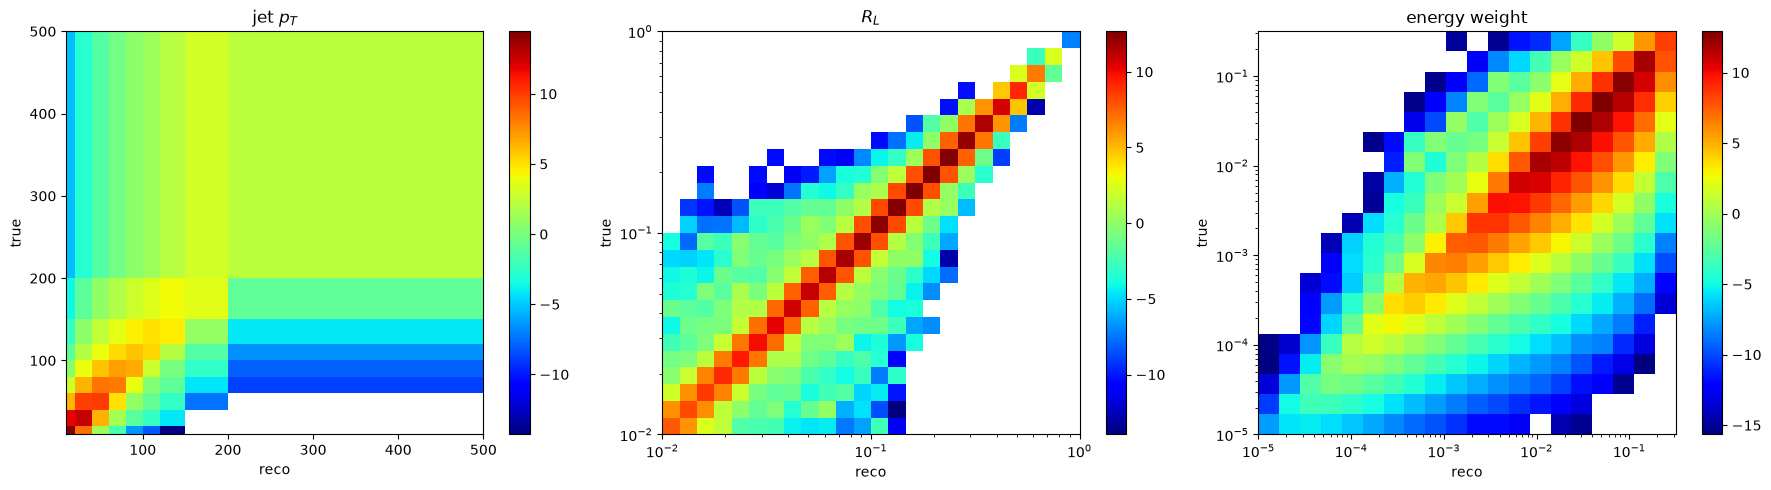

/tmp/ipykernel_226458/1751521545.py:35: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')


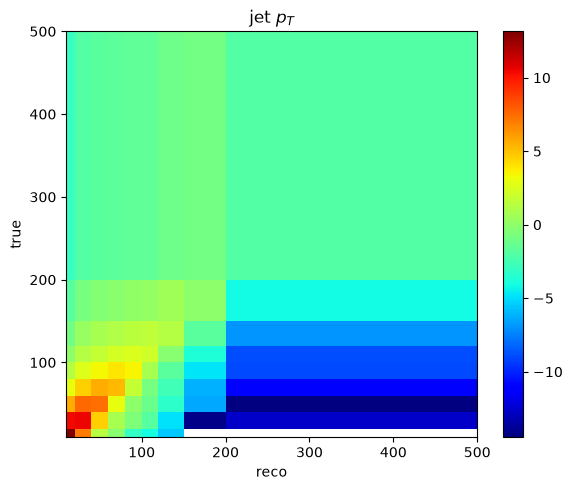

[array([2.27478553e+06, 4.73094731e+05, 4.28841962e+04, 8.10101044e+03,
       2.25101253e+03, 7.88419427e+02, 4.04127484e+02, 1.64534654e+02,
       4.61800674e+01]), array([3.43126977e+03, 5.19161852e+03, 7.84189386e+03, 1.19846410e+04,
       1.75407420e+04, 2.55427719e+04, 3.73973119e+04, 5.41056644e+04,
       7.69255788e+04, 1.08905592e+05, 1.48957639e+05, 2.01478086e+05,
       2.61350329e+05, 3.22260866e+05, 3.70157825e+05, 3.80852206e+05,
       3.37288940e+05, 2.42243508e+05, 1.29769758e+05, 4.75872500e+04,
       1.07948486e+04, 8.99877819e+02, 1.15291918e+01, 6.88805550e-04]), array([1.32689405e-02, 9.69611260e-02, 5.45385508e-01, 2.51224952e+00,
       1.02135788e+01, 3.82926056e+01, 1.35292785e+02, 4.59781461e+02,
       1.52584648e+03, 4.90654417e+03, 1.50980388e+04, 4.33224647e+04,
       1.14644983e+05, 2.67352401e+05, 4.85963573e+05, 6.49726992e+05,
       6.38423235e+05, 4.21637737e+05, 1.54634960e+05, 4.63622316e+03])]
[7.18980716e+06 1.49989783e+06 1.51156782e+05 3

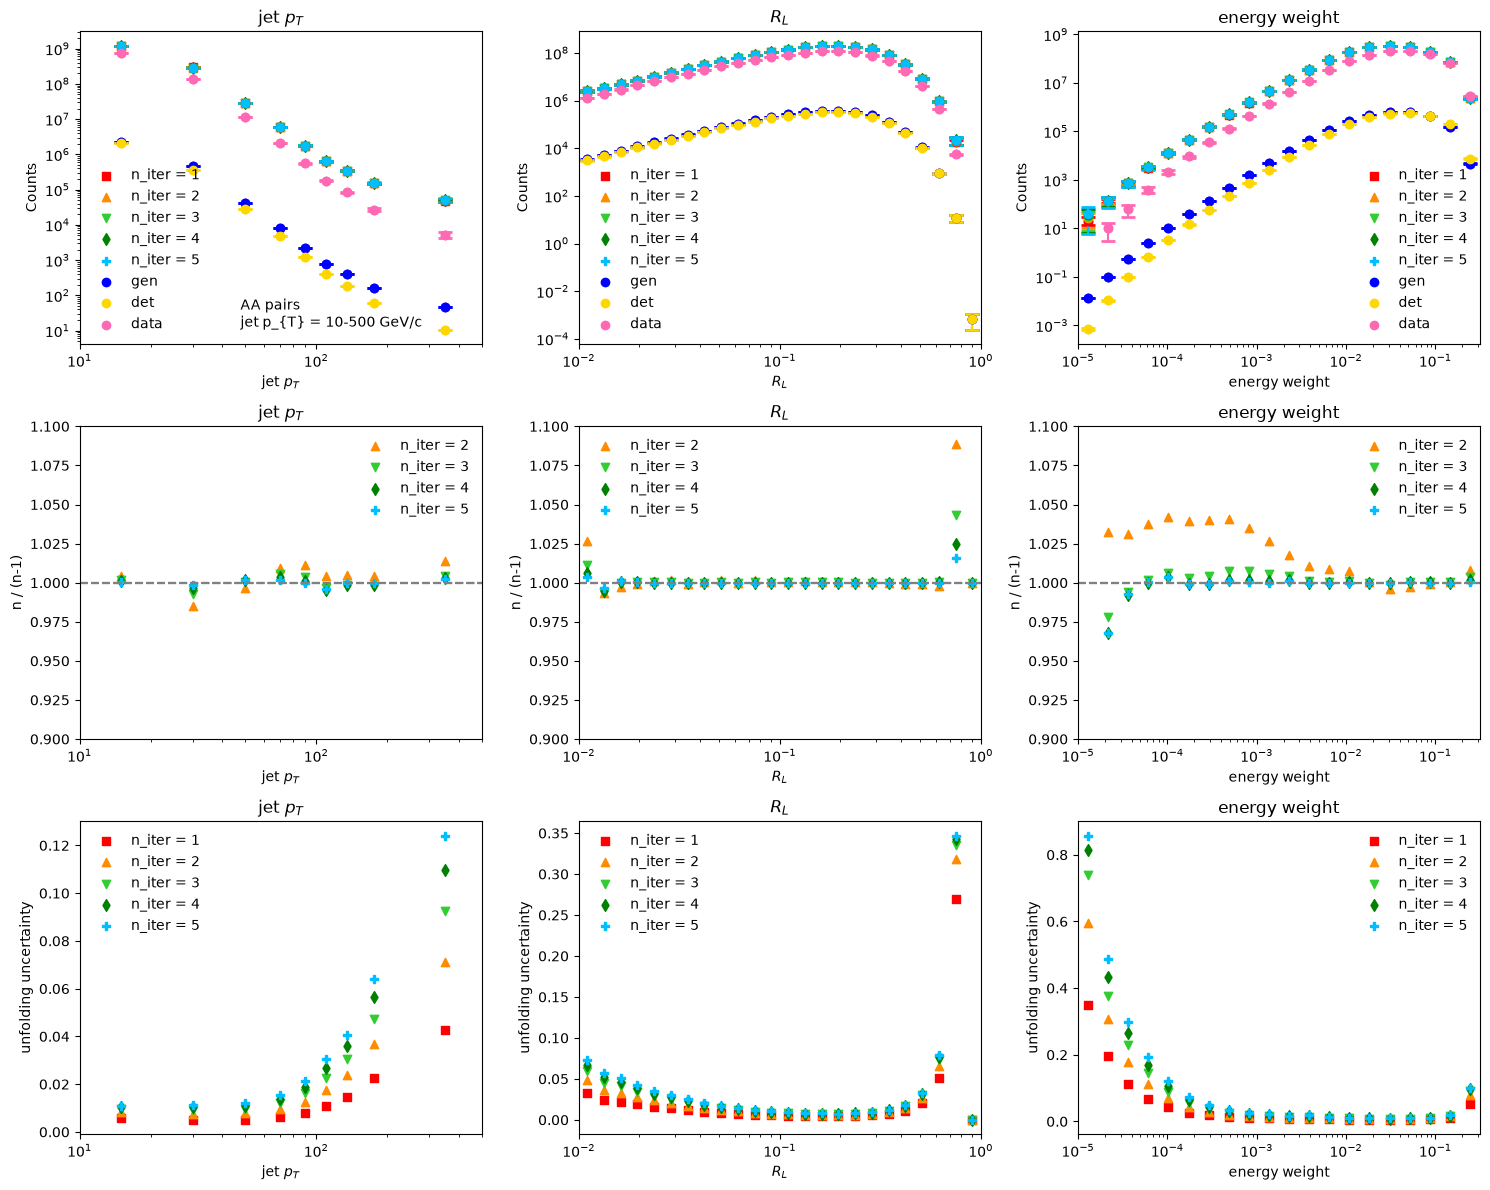

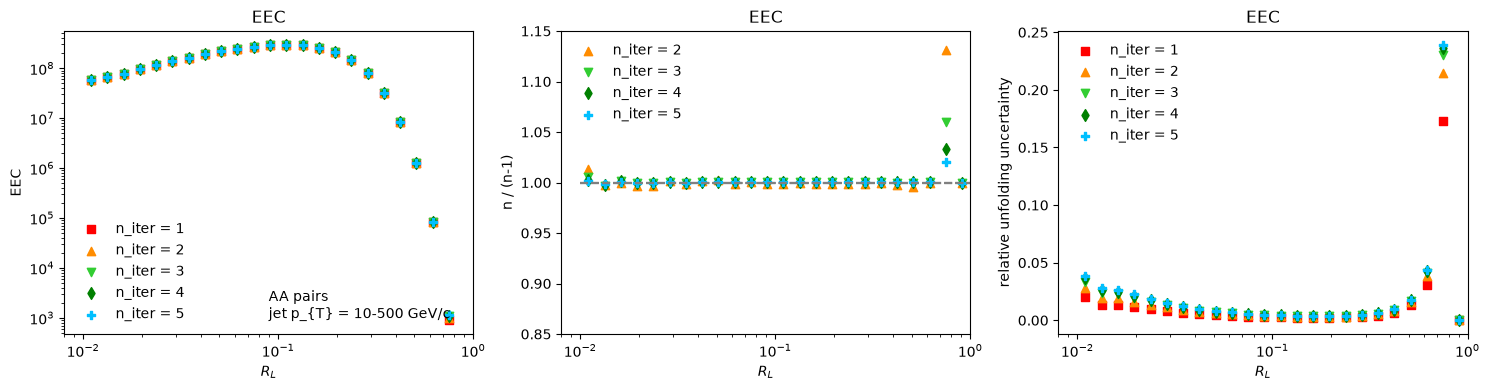

/tmp/ipykernel_226458/2950101171.py:94: RuntimeWarning: invalid value encountered in divide
  raw_EEC_relerr = raw_EEC_err / raw_EEC


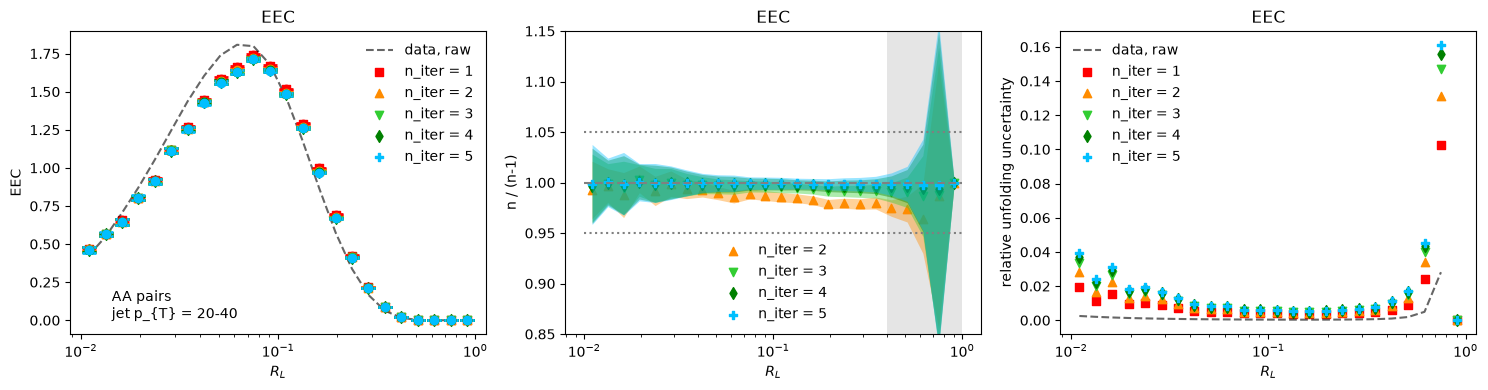

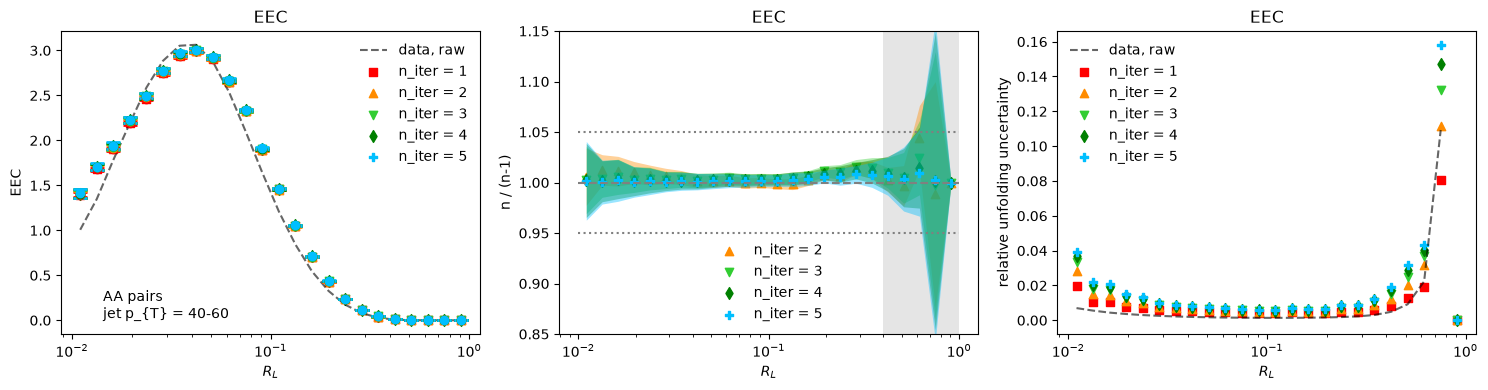

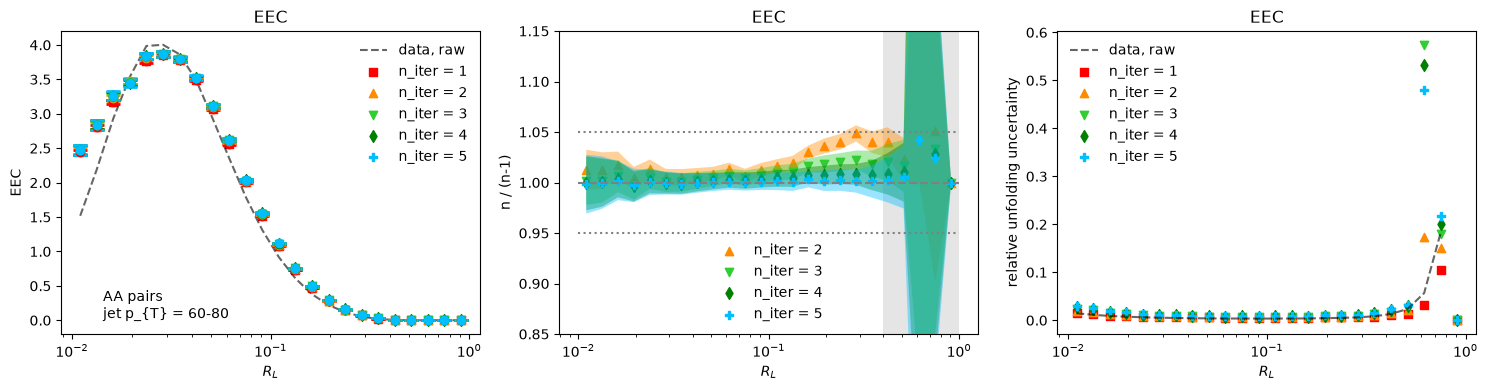

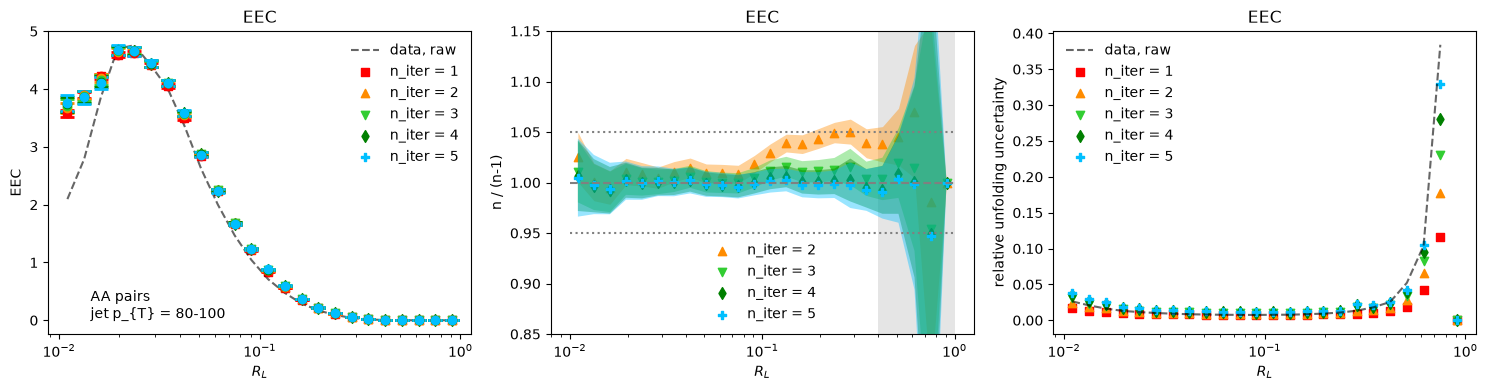

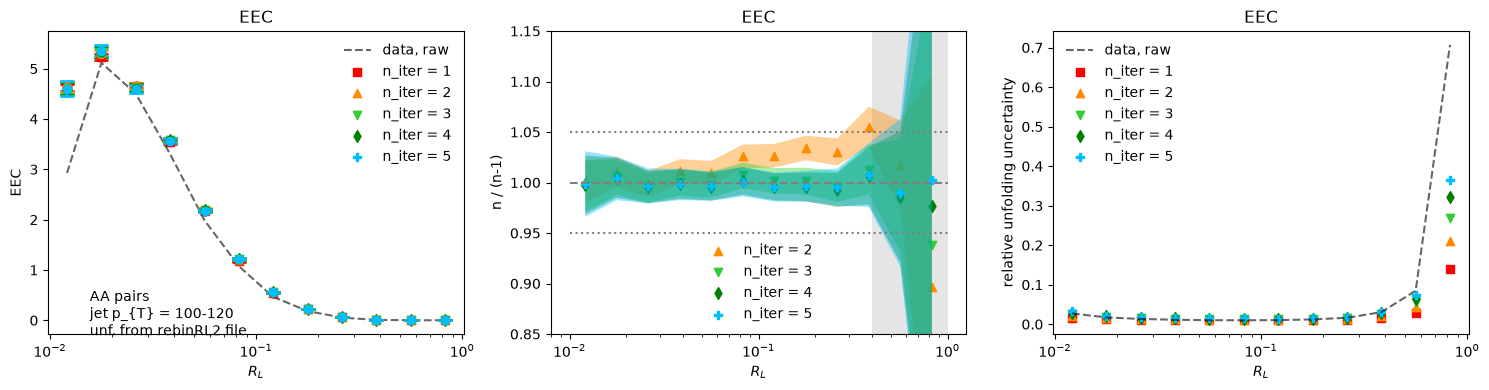

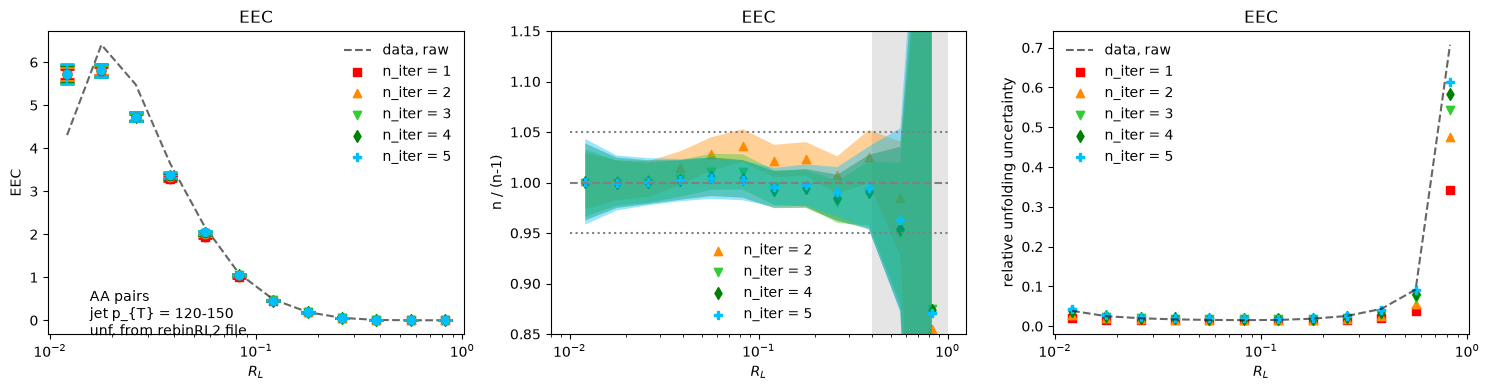

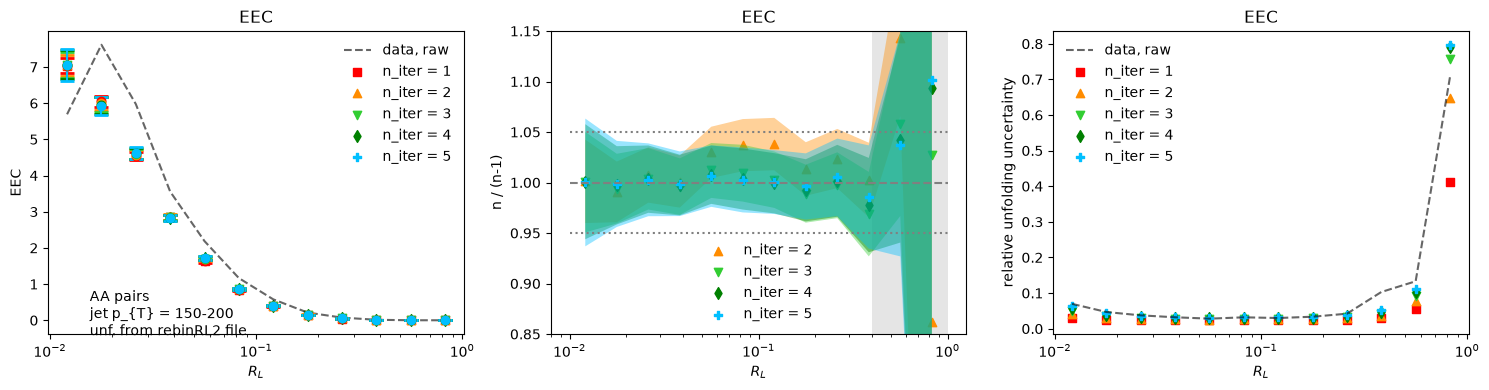

In [17]:
lab = "AA"
h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity = get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm) #, f_prefundold_gen)
matrix1D, matricies = get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true)
print_response_matricies(matrix1D, matricies, binning_reco, binning, labels)

theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err = get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded)
plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                        theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err)
plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning)

plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels,
                             h3_unfolded_rebin=h3_unfolded_rebinRL2[lab], rl_rebin_binning=rl_rebin_binning)



[[5.16742736e+05 3.14829077e+04 2.75343056e+02 2.00577977e+01
  3.48086339e+00 9.21779277e-01 4.01944440e-01 1.51319417e-01
  5.30398679e-02]
 [1.19231342e+03 3.85499396e+04 1.94667402e+03 1.03117481e+02
  1.41271548e+01 3.31988688e+00 1.33503479e+00 4.61882990e-01
  1.39368119e-01]
 [3.87227589e+00 9.31641216e+01 1.61364035e+03 2.55943953e+02
  3.09789032e+01 6.24403473e+00 2.18841351e+00 6.68947392e-01
  1.73305290e-01]
 [7.45596553e-01 2.27910188e+00 1.94507245e+01 1.89739656e+02
  5.17308221e+01 1.01900803e+01 3.27366480e+00 8.81378659e-01
  1.97409147e-01]
 [4.63160209e-02 5.65547205e-01 9.93964109e-01 5.93698024e+00
  3.49523671e+01 1.32400555e+01 4.33905999e+00 1.08580272e+00
  2.10620308e-01]
 [1.67585515e-02 1.48240252e-01 2.89538622e-01 4.41831671e-01
  2.19361771e+00 8.33350437e+00 4.78387993e+00 1.24514384e+00
  2.19285532e-01]
 [3.91490206e-03 7.39563548e-03 3.63808081e-02 7.05905256e-02
  1.67915562e-01 7.67867703e-01 3.41224762e+00 1.75012005e+00
  3.17605385e-01]
 [0.00

/tmp/ipykernel_226458/1751521545.py:16: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


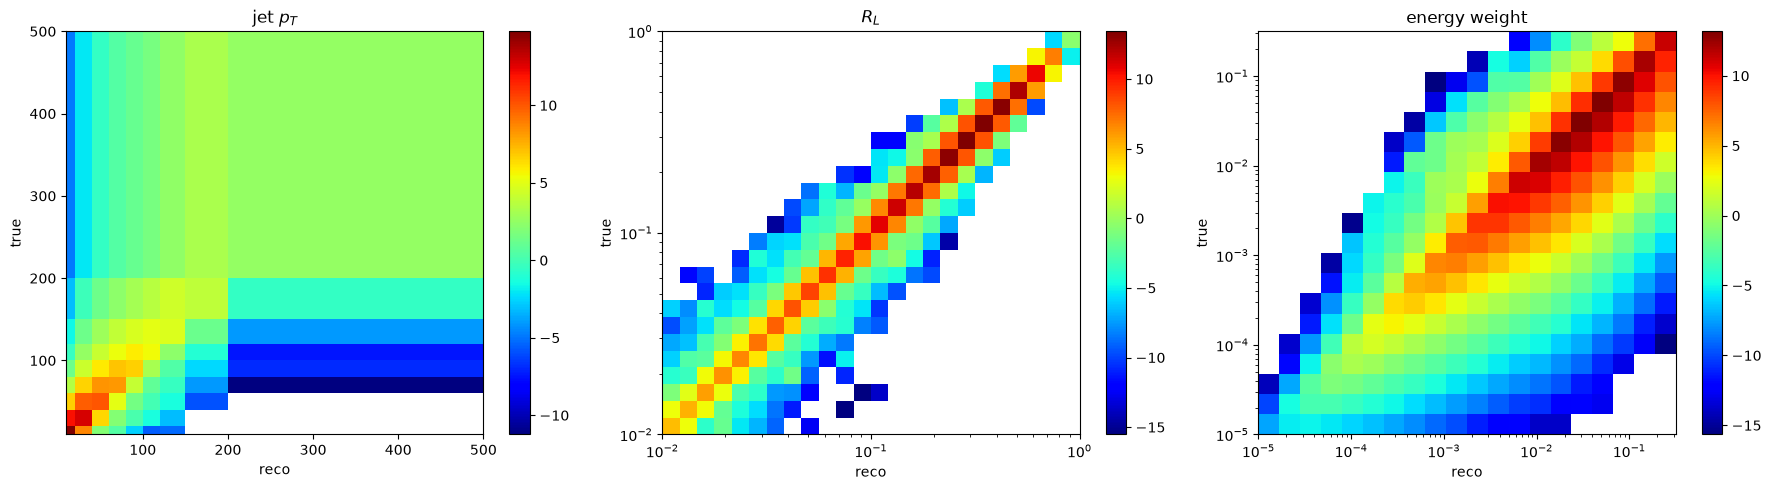

/tmp/ipykernel_226458/1751521545.py:35: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')


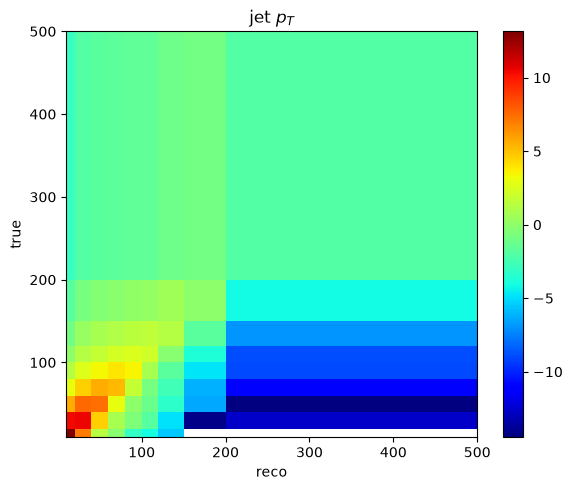

[array([3.16035196e+06, 5.14793189e+05, 4.36028413e+04, 8.42548568e+03,
       2.42176363e+03, 8.75330880e+02, 4.65149735e+02, 1.97123721e+02,
       5.91475560e+01]), array([1.77169138e+02, 2.51185377e+02, 4.24709057e+02, 6.12905346e+02,
       9.31804872e+02, 1.55186855e+03, 2.59937894e+03, 4.00925756e+03,
       6.62745991e+03, 1.10074132e+04, 1.86322102e+04, 3.25792807e+04,
       5.71786307e+04, 1.01824125e+05, 1.80792671e+05, 3.14233300e+05,
       5.12653603e+05, 7.34213949e+05, 8.33350790e+05, 6.08786719e+05,
       2.58671572e+05, 4.89562870e+04, 1.12513025e+03, 5.67836228e-01]), array([2.04365112e-02, 1.46319068e-01, 7.93120907e-01, 3.57152602e+00,
       1.42492153e+01, 5.24551570e+01, 1.82292637e+02, 6.08851669e+02,
       1.99201999e+03, 6.33214371e+03, 1.92887158e+04, 5.52940141e+04,
       1.50461002e+05, 3.73611935e+05, 6.74799929e+05, 8.55217115e+05,
       7.81090932e+05, 5.01197440e+05, 2.25992653e+05, 8.50517077e+04])]
[7.02510811e+06 1.39769389e+06 1.42280124e+05 3

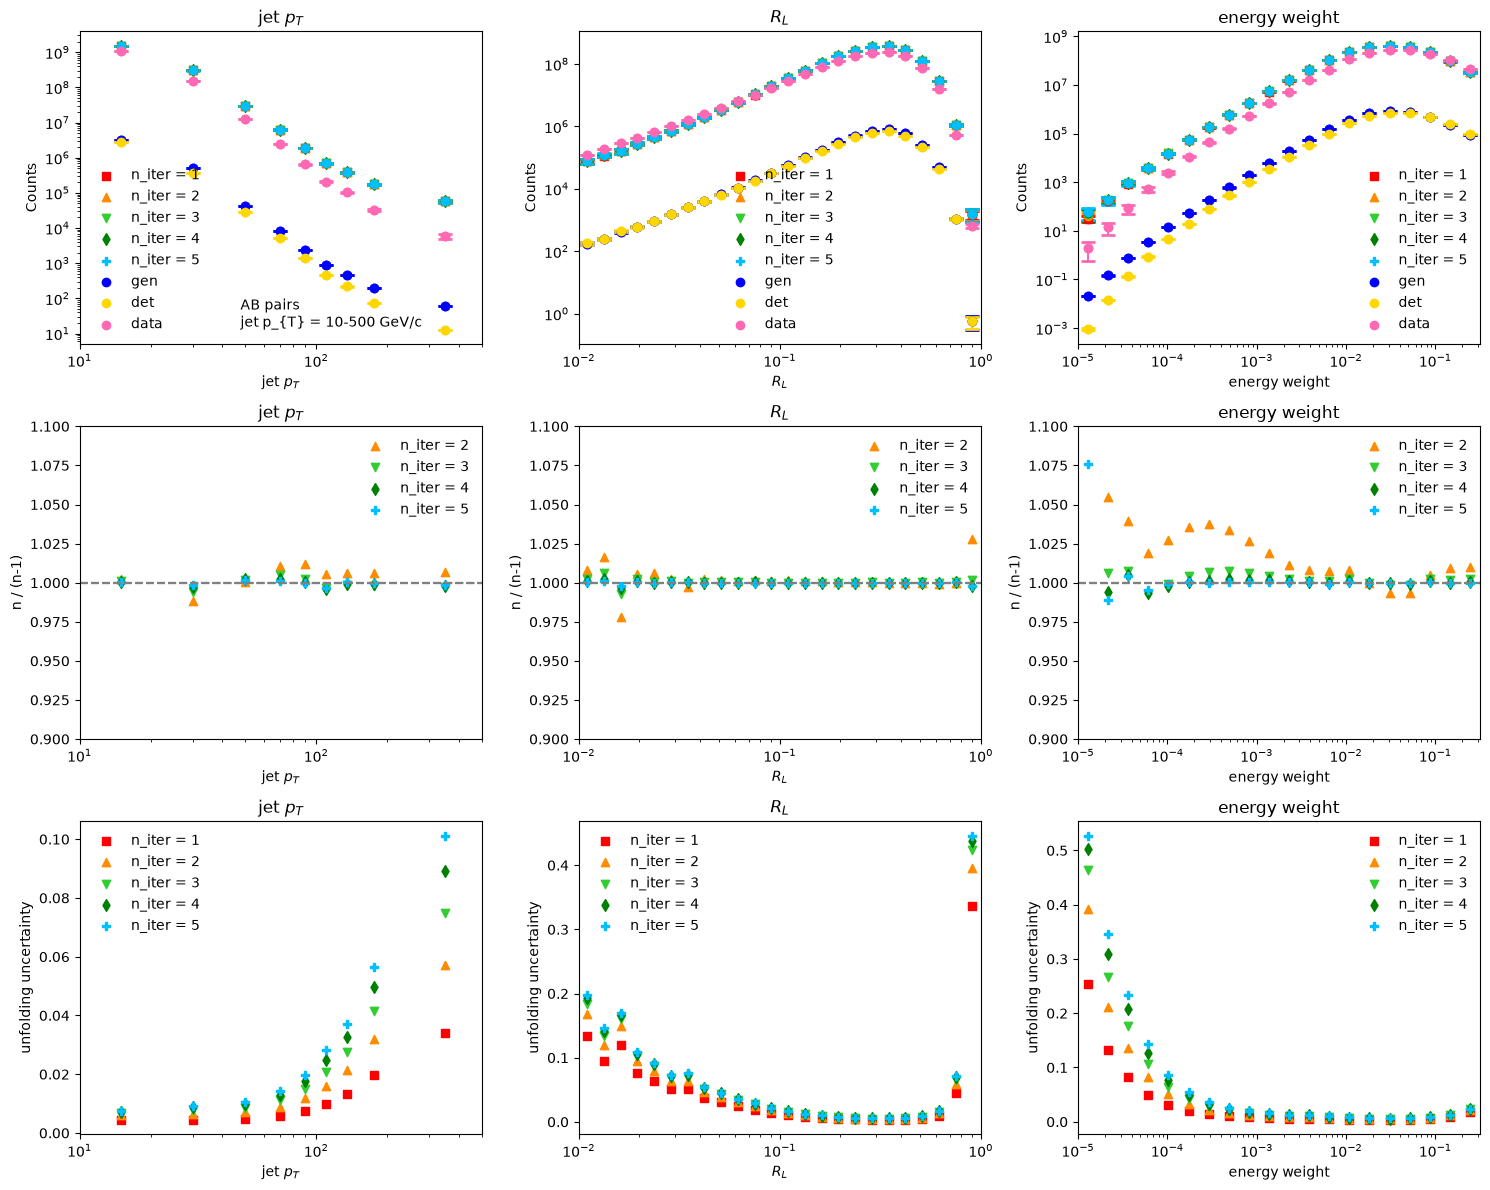

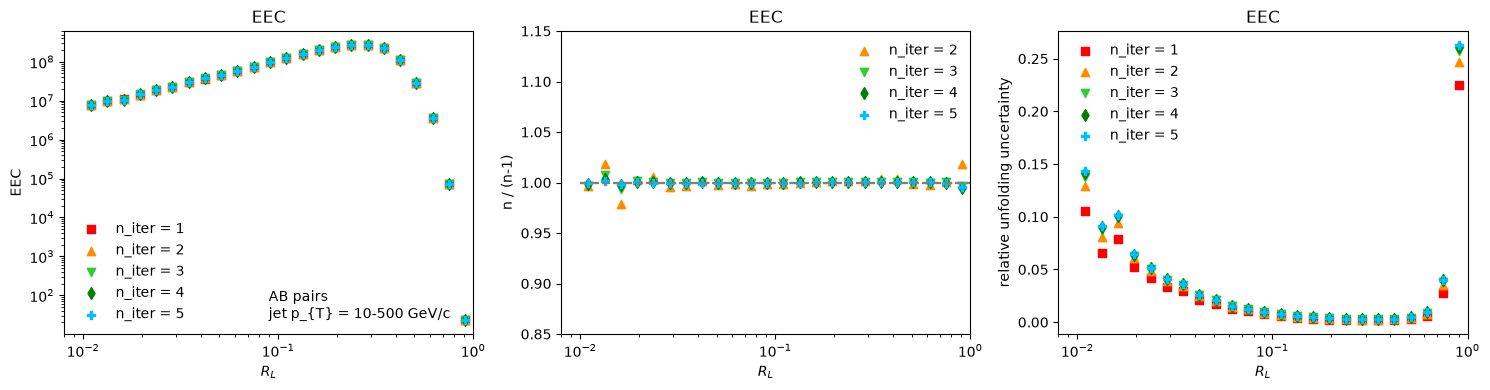

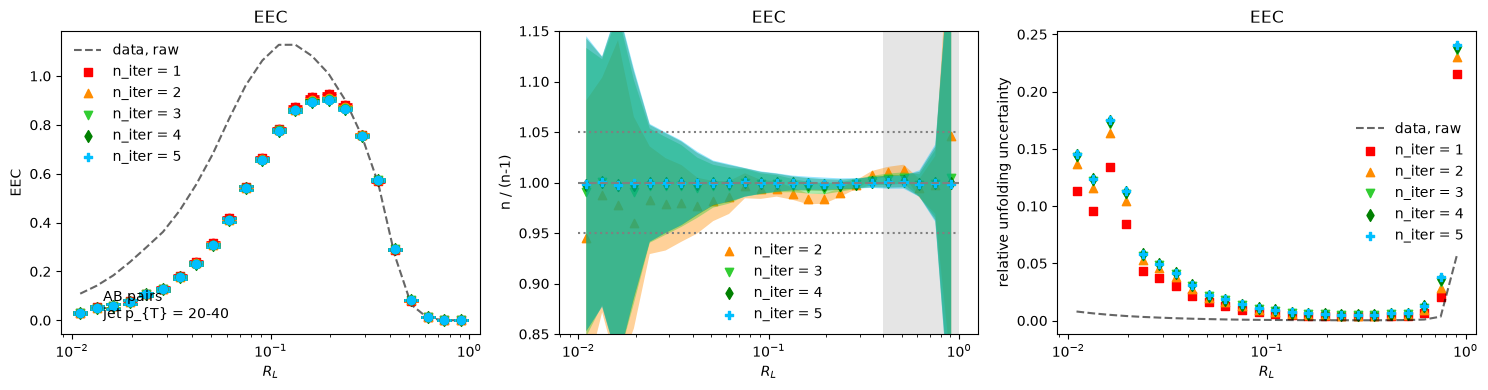

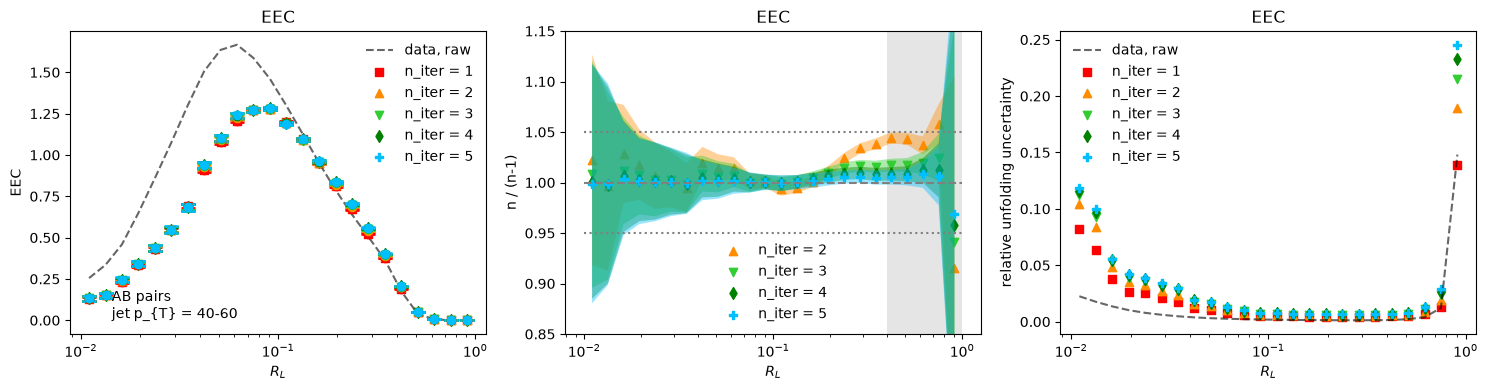

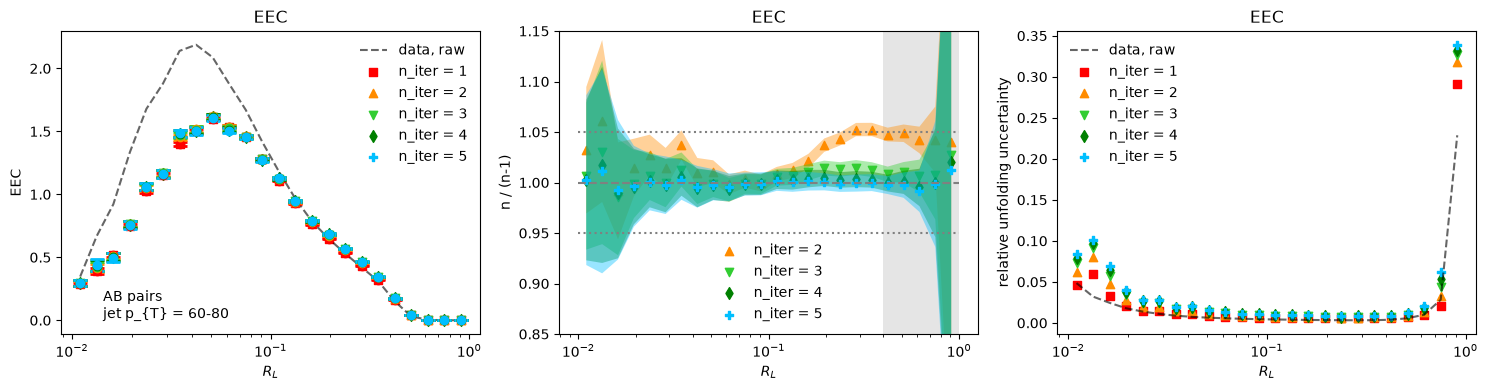

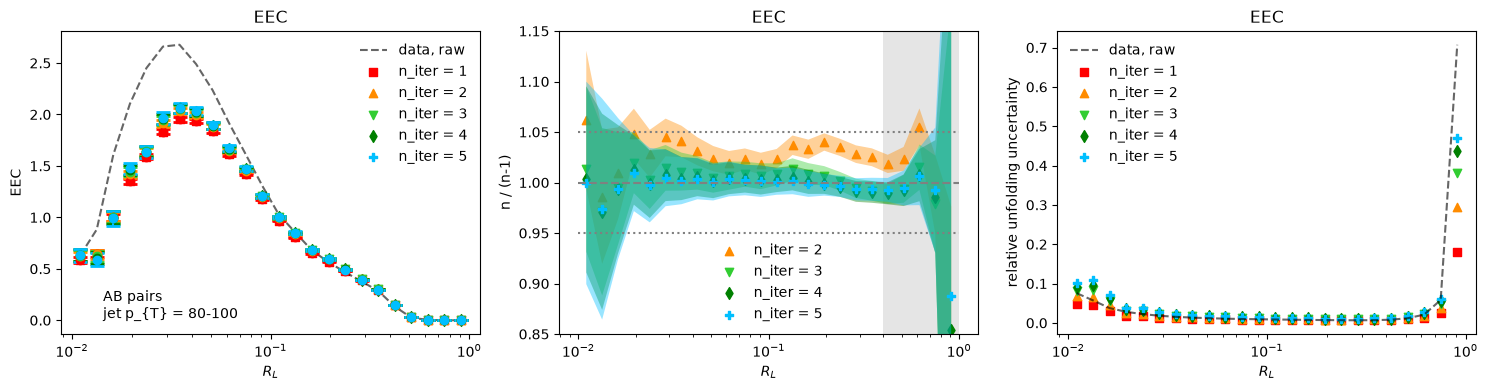

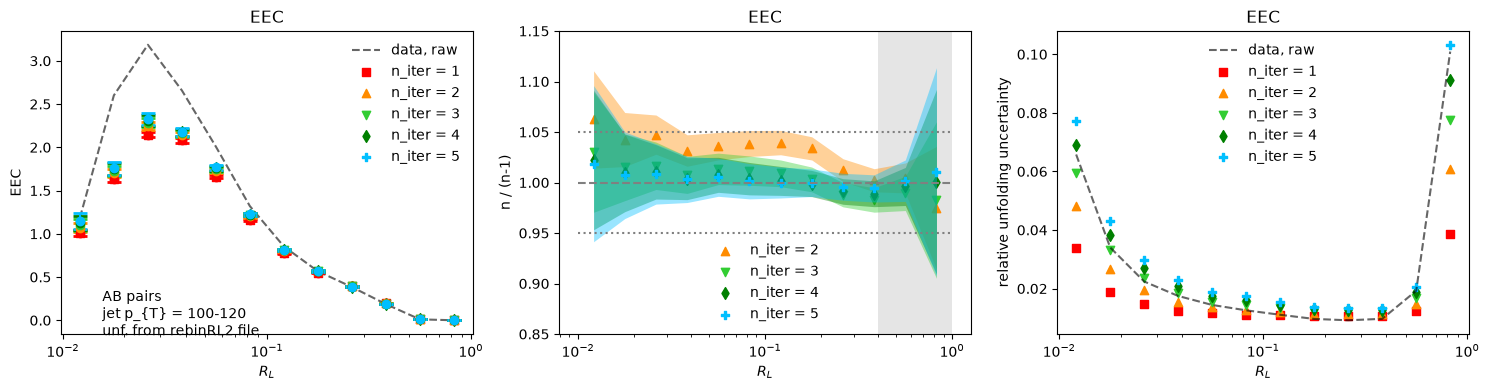

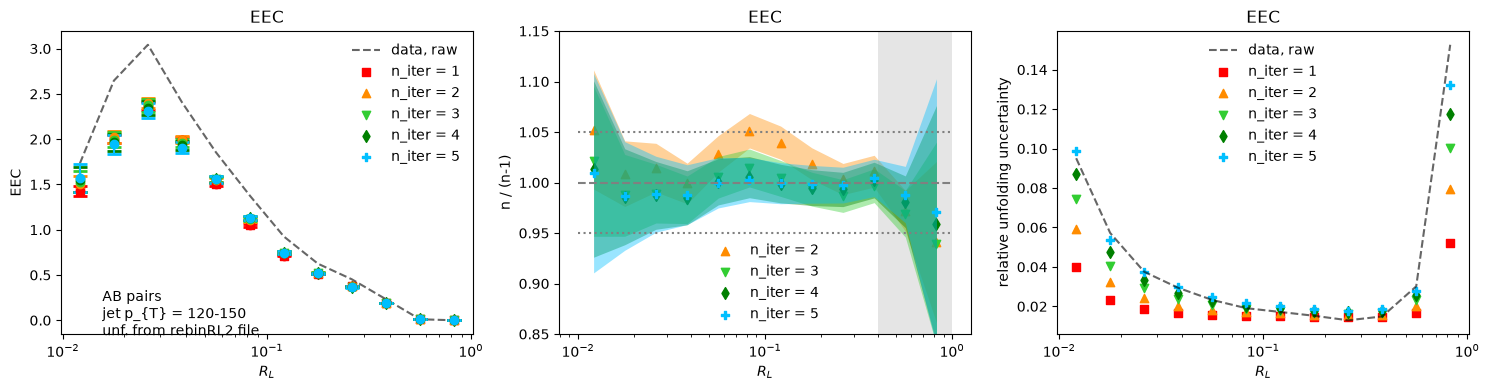

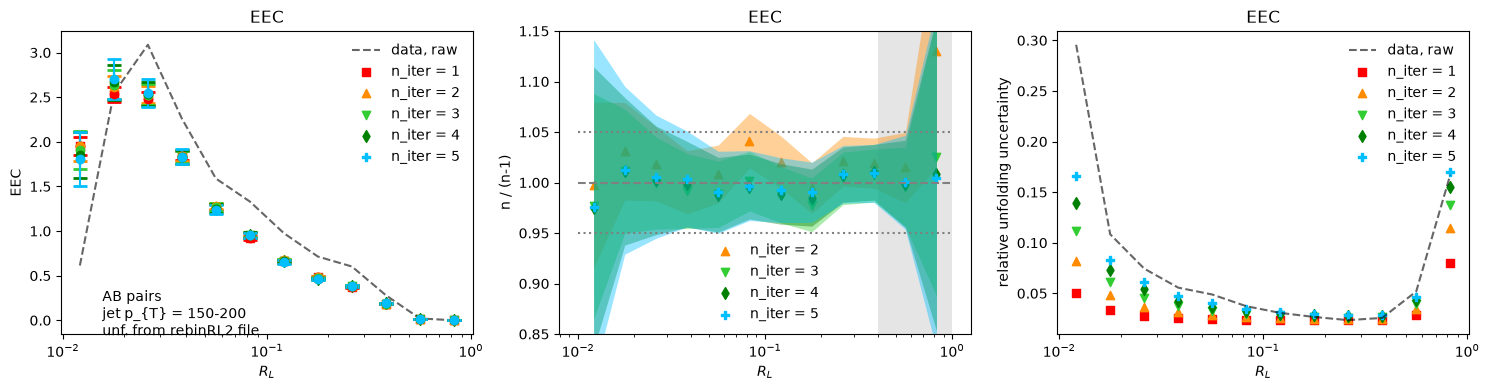

In [18]:
lab = "AB"
h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity = get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm) #, f_prefundold_gen)
matrix1D, matricies = get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true)
print_response_matricies(matrix1D, matricies, binning_reco, binning, labels)

theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err = get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded)
plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                        theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err)
plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning)

plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels,
                             h3_unfolded_rebin=h3_unfolded_rebinRL2[lab], rl_rebin_binning=rl_rebin_binning)


[[5.16742736e+05 3.14829077e+04 2.75343056e+02 2.00577977e+01
  3.48086339e+00 9.21779277e-01 4.01944440e-01 1.51319417e-01
  5.30398679e-02]
 [1.19231342e+03 3.85499396e+04 1.94667402e+03 1.03117481e+02
  1.41271548e+01 3.31988688e+00 1.33503479e+00 4.61882990e-01
  1.39368119e-01]
 [3.87227589e+00 9.31641216e+01 1.61364035e+03 2.55943953e+02
  3.09789032e+01 6.24403473e+00 2.18841351e+00 6.68947392e-01
  1.73305290e-01]
 [7.45596553e-01 2.27910188e+00 1.94507245e+01 1.89739656e+02
  5.17308221e+01 1.01900803e+01 3.27366480e+00 8.81378659e-01
  1.97409147e-01]
 [4.63160209e-02 5.65547205e-01 9.93964109e-01 5.93698024e+00
  3.49523671e+01 1.32400555e+01 4.33905999e+00 1.08580272e+00
  2.10620308e-01]
 [1.67585515e-02 1.48240252e-01 2.89538622e-01 4.41831671e-01
  2.19361771e+00 8.33350437e+00 4.78387993e+00 1.24514384e+00
  2.19285532e-01]
 [3.91490206e-03 7.39563548e-03 3.63808081e-02 7.05905256e-02
  1.67915562e-01 7.67867703e-01 3.41224762e+00 1.75012005e+00
  3.17605385e-01]
 [0.00

/tmp/ipykernel_226458/1751521545.py:16: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


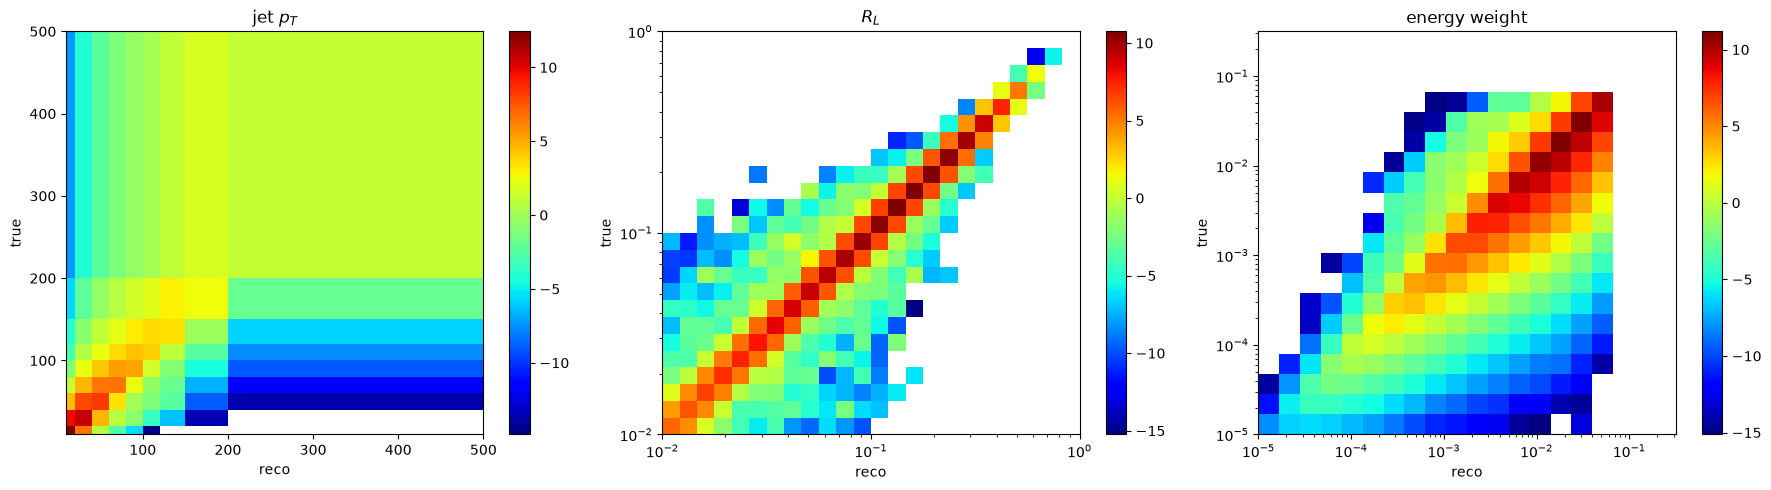

/tmp/ipykernel_226458/1751521545.py:35: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')


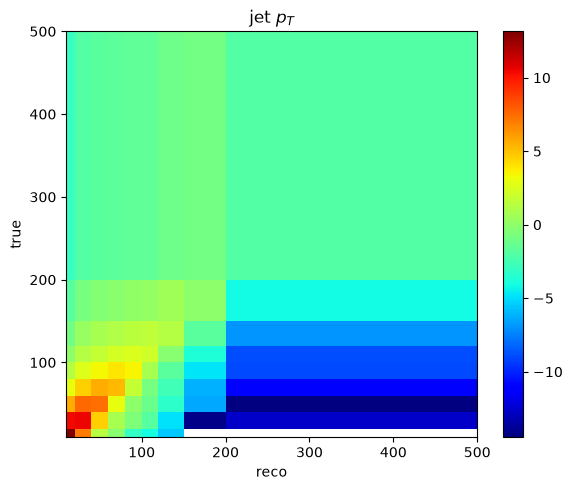

[array([2.84468329e+05, 6.68923835e+04, 7.14550918e+03, 1.56777812e+03,
       4.91399316e+02, 1.89728154e+02, 1.06559884e+02, 4.78663269e+01,
       1.49921010e+01]), array([4.78611222e+02, 6.79067765e+02, 1.06921087e+03, 1.59272113e+03,
       2.32565280e+03, 3.33613357e+03, 5.11987770e+03, 7.28448651e+03,
       1.05623454e+04, 1.51182342e+04, 2.10623429e+04, 2.89182900e+04,
       3.78710700e+04, 4.81393752e+04, 5.31810379e+04, 5.14087367e+04,
       3.89052070e+04, 2.29174659e+04, 8.99730947e+03, 1.78645071e+03,
       1.67069258e+02, 3.84622899e+00, 3.35175657e-03, 0.00000000e+00]), array([7.13900046e-03, 5.41769859e-02, 2.97714124e-01, 1.33973831e+00,
       5.39740877e+00, 1.94939938e+01, 6.65858680e+01, 2.17648754e+02,
       6.82171035e+02, 2.06855796e+03, 6.48037417e+03, 1.68669927e+04,
       3.75441332e+04, 7.47846194e+04, 1.04301871e+05, 8.68251115e+04,
       3.10598896e+04, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00])]
[2.62870503e+06 5.84446530e+05 6.19732359e+04 1

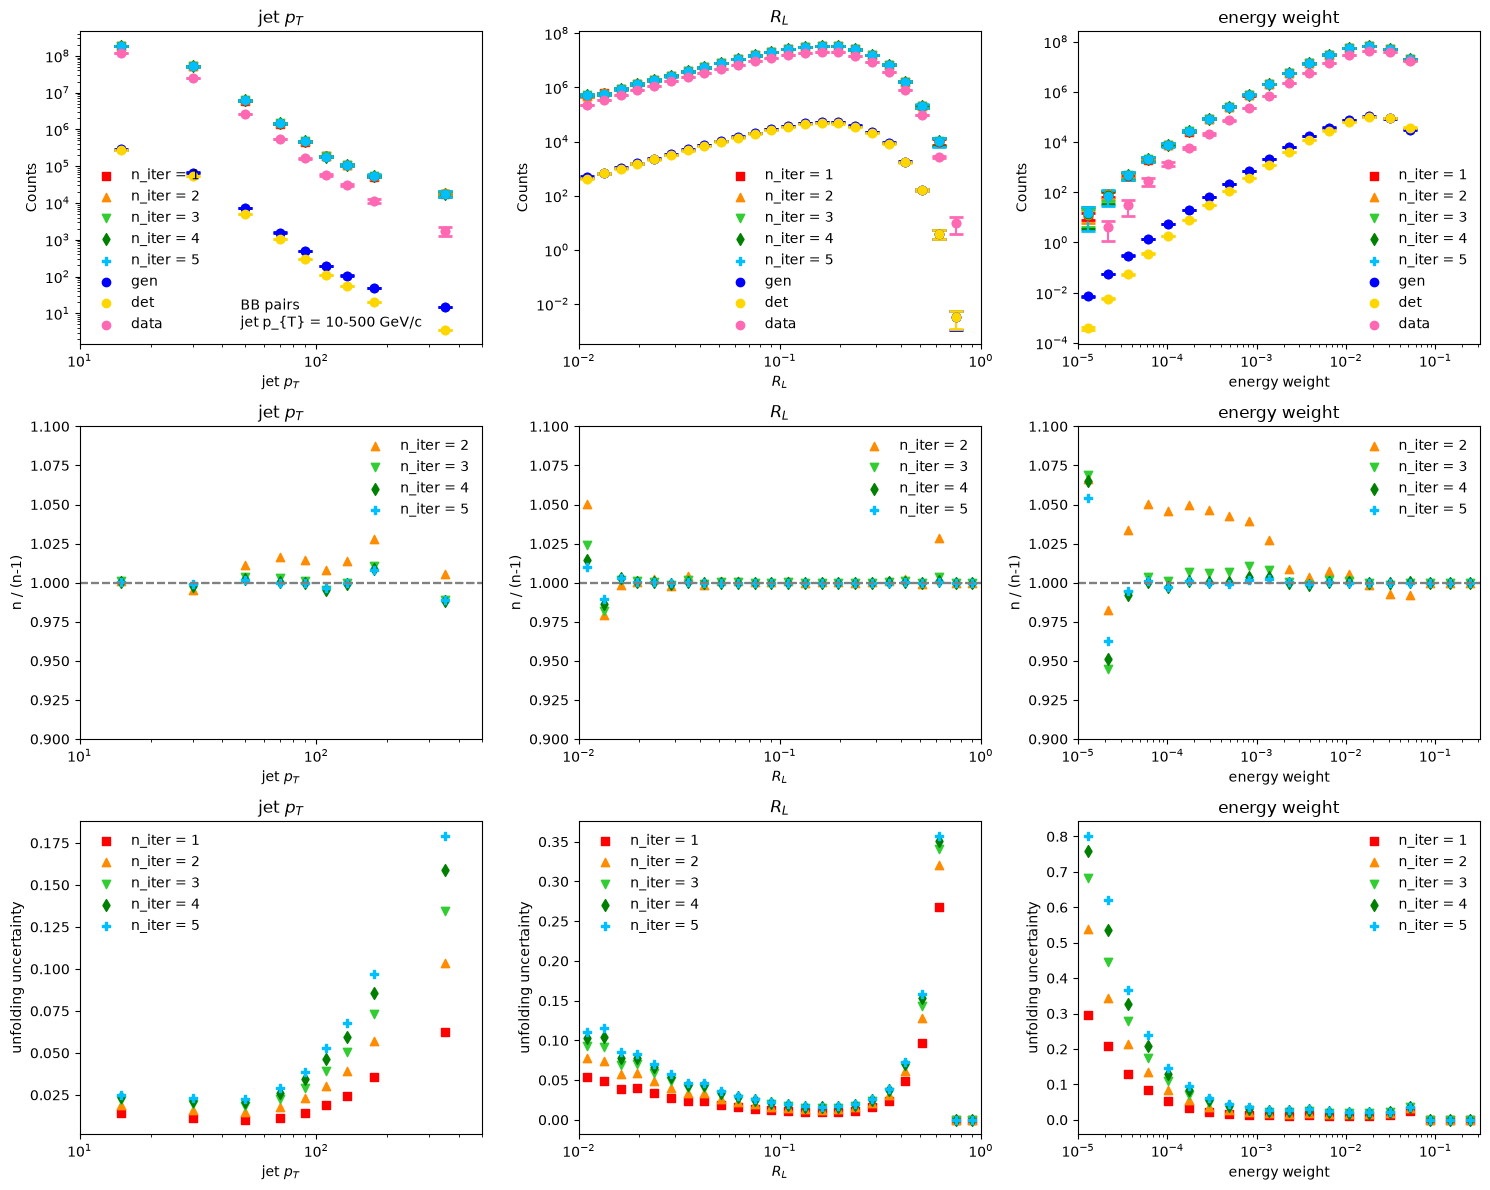

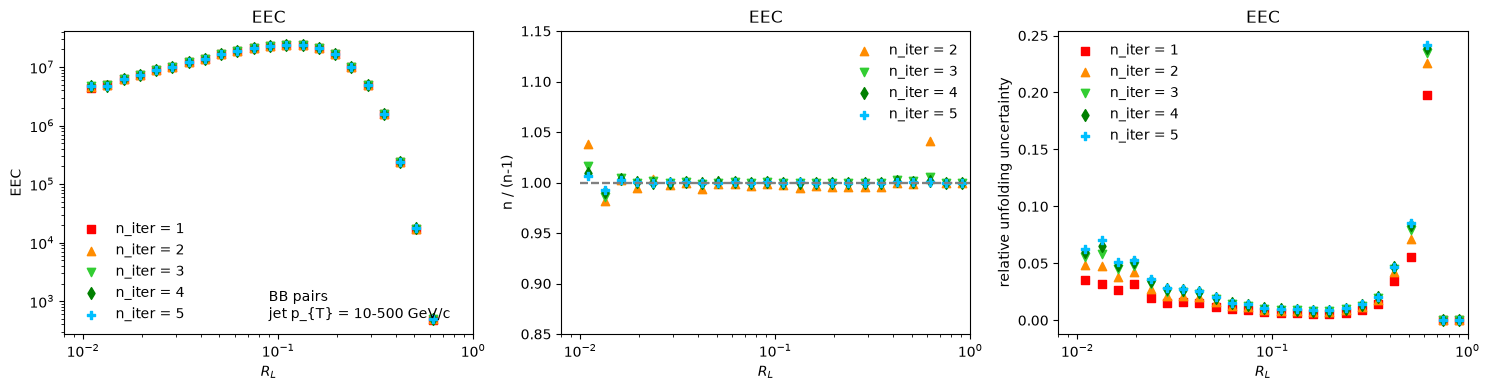

/tmp/ipykernel_226458/2950101171.py:94: RuntimeWarning: invalid value encountered in divide
  raw_EEC_relerr = raw_EEC_err / raw_EEC


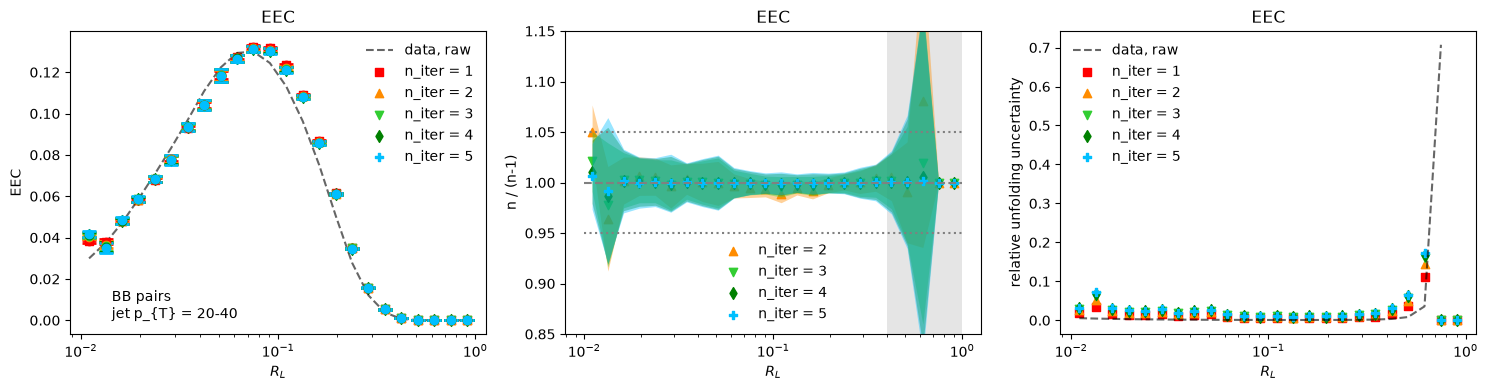

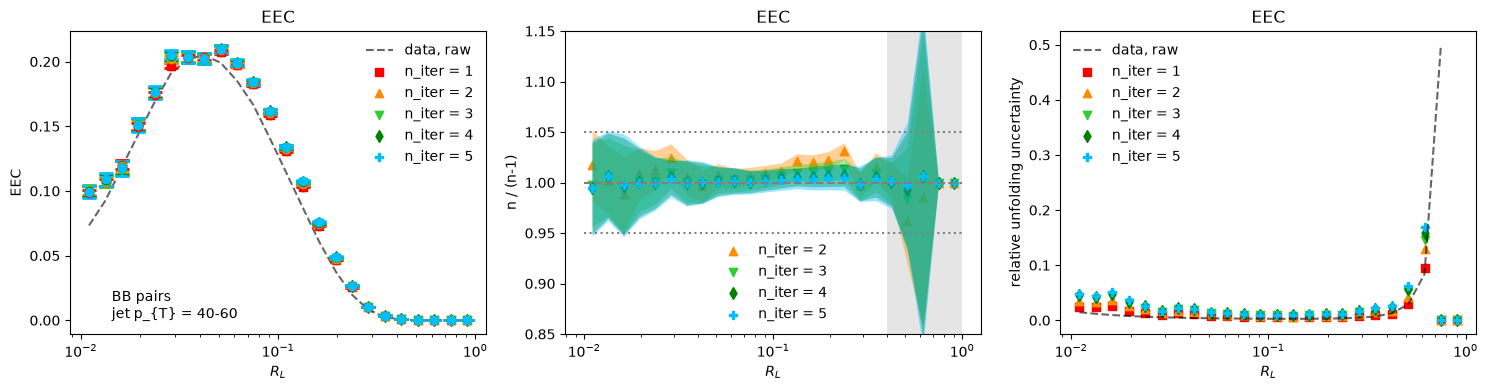

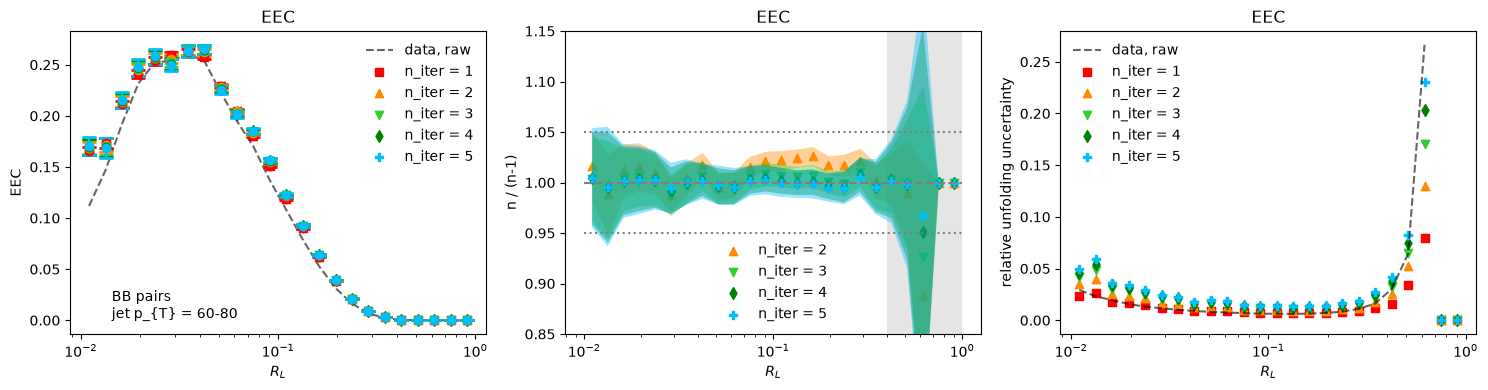

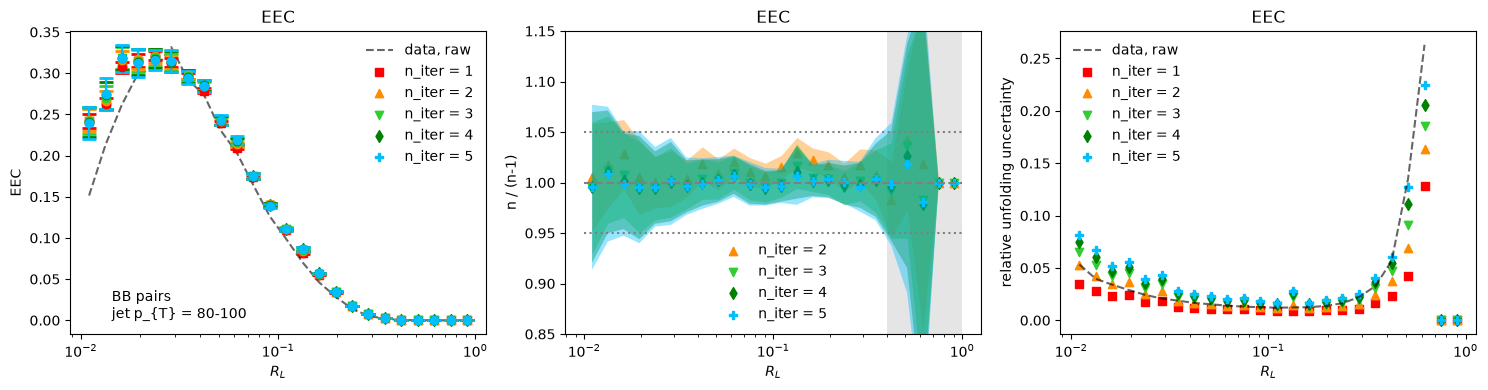

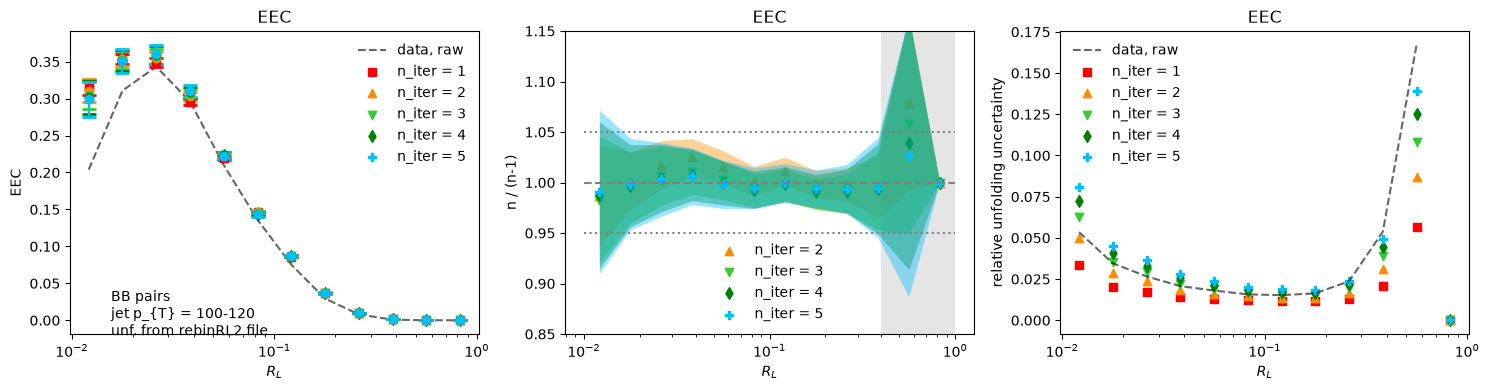

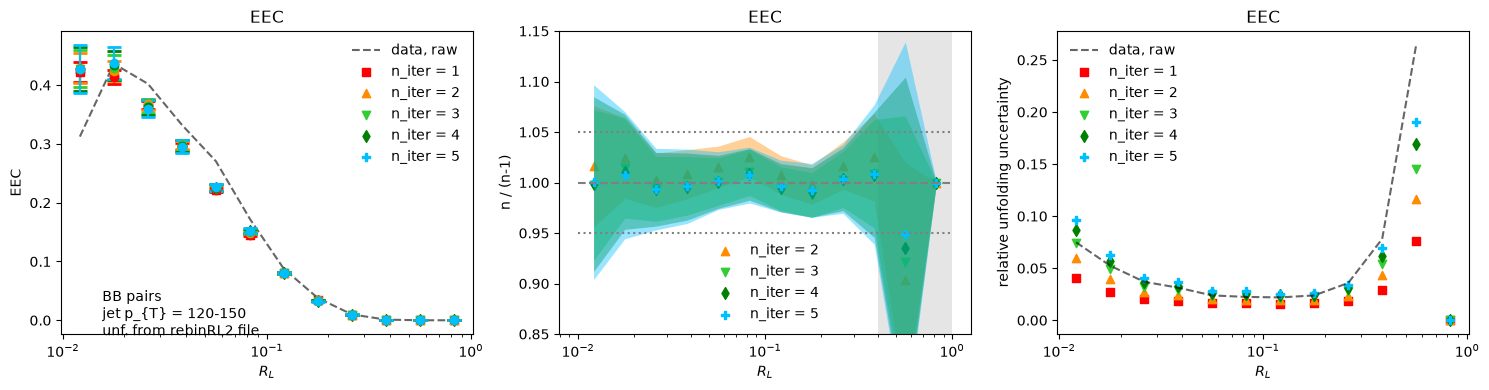

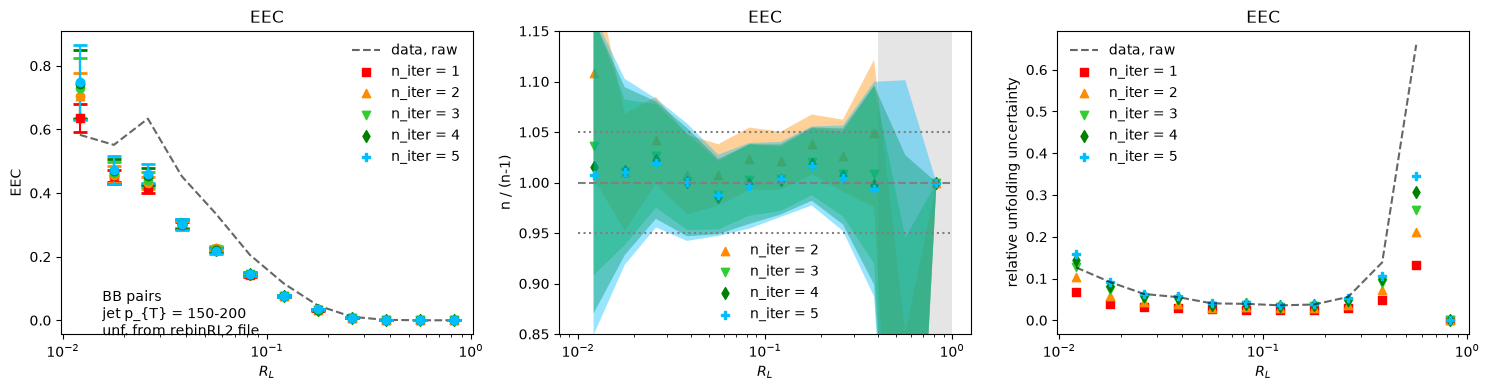

In [19]:
lab = "BB"
h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity = get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm) #, f_prefundold_gen)
matrix1D, matricies = get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true)
print_response_matricies(matrix1D, matricies, binning_reco, binning, labels)

theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err = get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded)
plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                        theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err)
plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning)

plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels,
                             h3_unfolded_rebin=h3_unfolded_rebinRL2[lab], rl_rebin_binning=rl_rebin_binning)


[[5.16742736e+05 3.14829077e+04 2.75343056e+02 2.00577977e+01
  3.48086339e+00 9.21779277e-01 4.01944440e-01 1.51319417e-01
  5.30398679e-02]
 [1.19231342e+03 3.85499396e+04 1.94667402e+03 1.03117481e+02
  1.41271548e+01 3.31988688e+00 1.33503479e+00 4.61882990e-01
  1.39368119e-01]
 [3.87227589e+00 9.31641216e+01 1.61364035e+03 2.55943953e+02
  3.09789032e+01 6.24403473e+00 2.18841351e+00 6.68947392e-01
  1.73305290e-01]
 [7.45596553e-01 2.27910188e+00 1.94507245e+01 1.89739656e+02
  5.17308221e+01 1.01900803e+01 3.27366480e+00 8.81378659e-01
  1.97409147e-01]
 [4.63160209e-02 5.65547205e-01 9.93964109e-01 5.93698024e+00
  3.49523671e+01 1.32400555e+01 4.33905999e+00 1.08580272e+00
  2.10620308e-01]
 [1.67585515e-02 1.48240252e-01 2.89538622e-01 4.41831671e-01
  2.19361771e+00 8.33350437e+00 4.78387993e+00 1.24514384e+00
  2.19285532e-01]
 [3.91490206e-03 7.39563548e-03 3.63808081e-02 7.05905256e-02
  1.67915562e-01 7.67867703e-01 3.41224762e+00 1.75012005e+00
  3.17605385e-01]
 [0.00

/tmp/ipykernel_226458/1751521545.py:16: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[i], binning[i], np.log(h).T, cmap='jet')


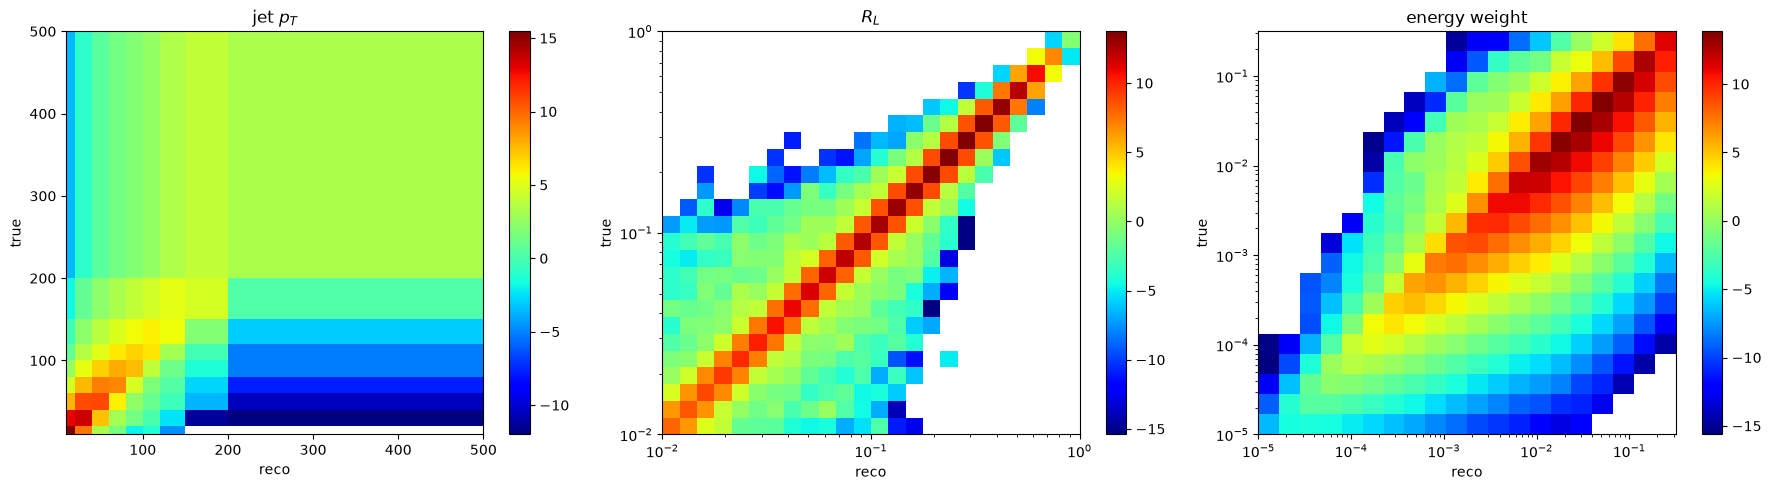

/tmp/ipykernel_226458/1751521545.py:35: RuntimeWarning: divide by zero encountered in log
  plot = ax.pcolormesh(binning_reco[0], binning[0], np.log(h).T, cmap='jet') #ax.pcolormesh(binning_reco[2], binning[2], np.log(h).T, cmap='jet')


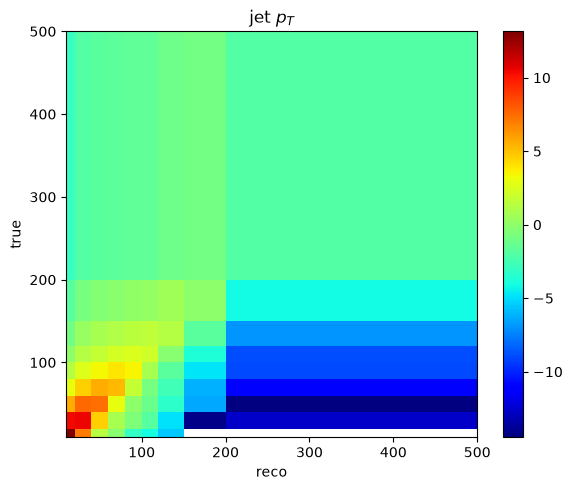

[array([6.46229459e+06, 1.23164338e+06, 1.09347020e+05, 2.10776872e+04,
       6.00355438e+03, 2.15385328e+03, 1.13464434e+03, 4.77838852e+02,
       1.42354486e+02]), array([4.49636324e+03, 6.73568800e+03, 1.02522173e+04, 1.56348133e+04,
       2.29702362e+04, 3.36384901e+04, 4.96654563e+04, 7.24946014e+04,
       1.04608068e+05, 1.50300472e+05, 2.11574254e+05, 2.96827811e+05,
       4.06857215e+05, 5.45964329e+05, 7.07893220e+05, 8.83341401e+05,
       1.04657780e+06, 1.14884455e+06, 1.07615596e+06, 7.05196780e+05,
       2.81947922e+05, 5.11504029e+04, 1.14631008e+03, 5.68525529e-01]), array([5.15039883e-02, 3.66650209e-01, 1.98252422e+00, 8.89993298e+00,
       3.55890141e+01, 1.30941754e+02, 4.56336332e+02, 1.53114064e+03,
       5.01731872e+03, 1.59633556e+04, 4.91033013e+04, 1.38784865e+05,
       3.62115733e+05, 8.42802355e+05, 1.46140310e+06, 1.80733173e+06,
       1.61534832e+06, 1.01445647e+06, 4.26812864e+05, 9.29702001e+04])]
[1.09595269e+07 2.21787799e+06 2.26775129e+05 5

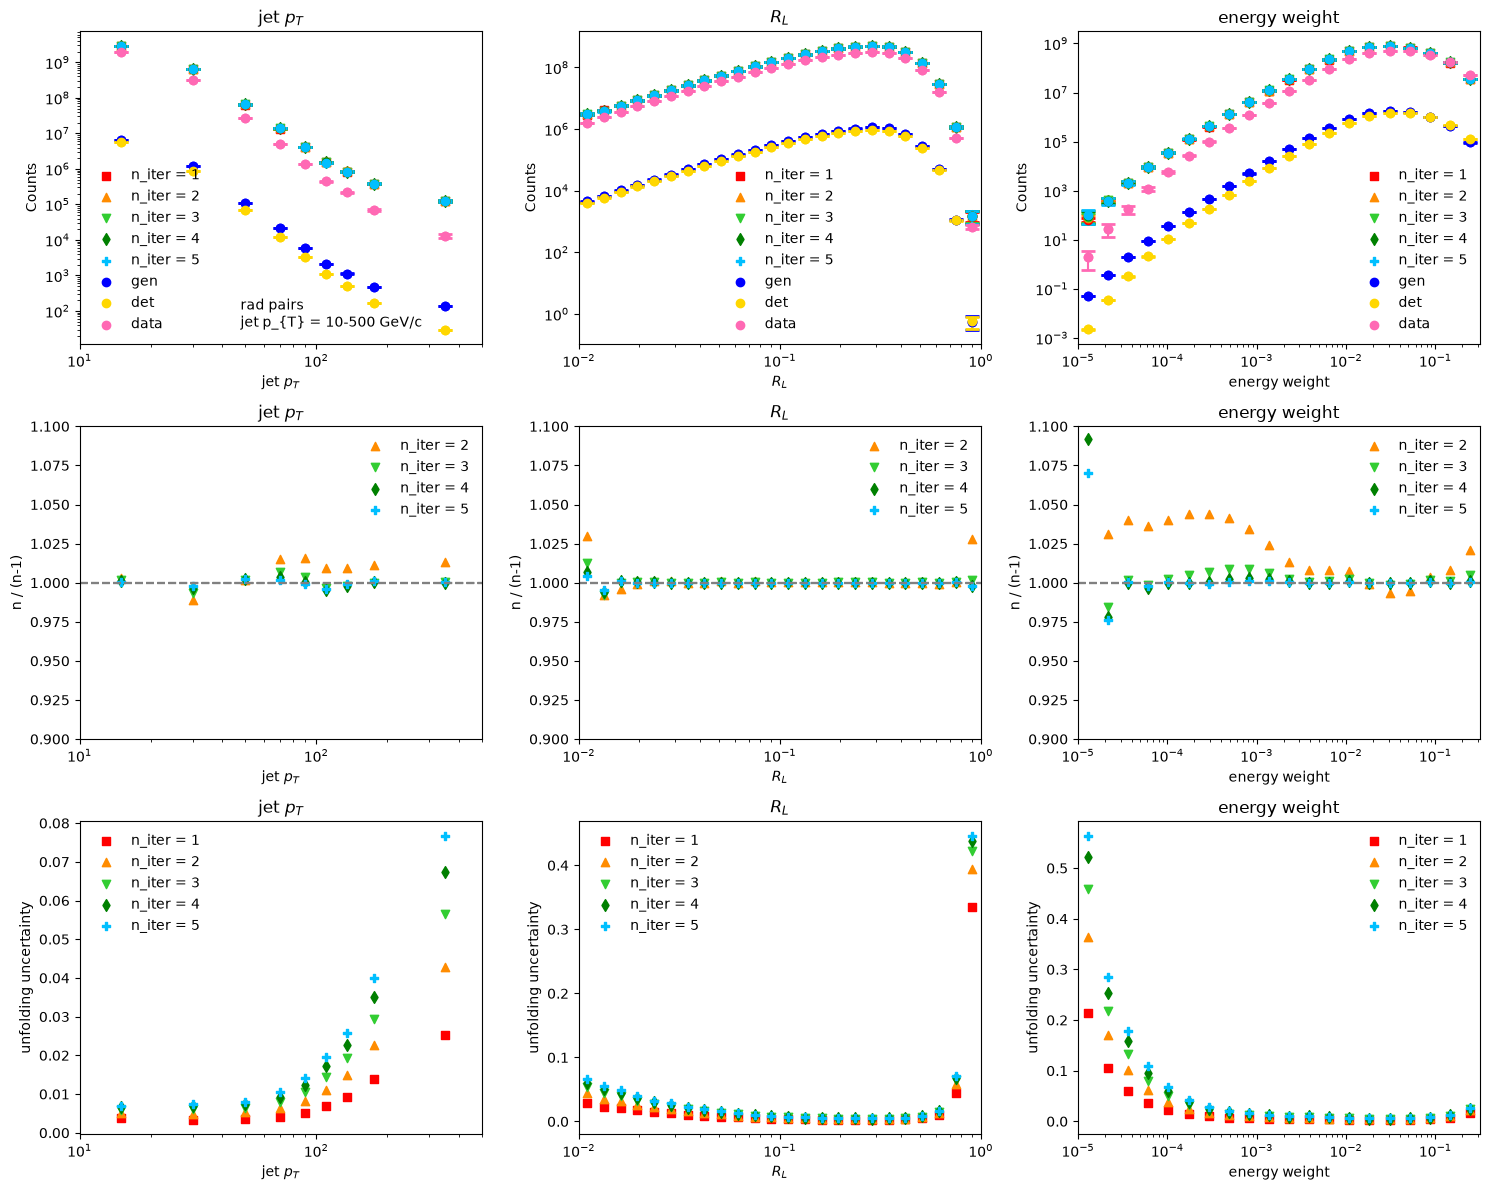

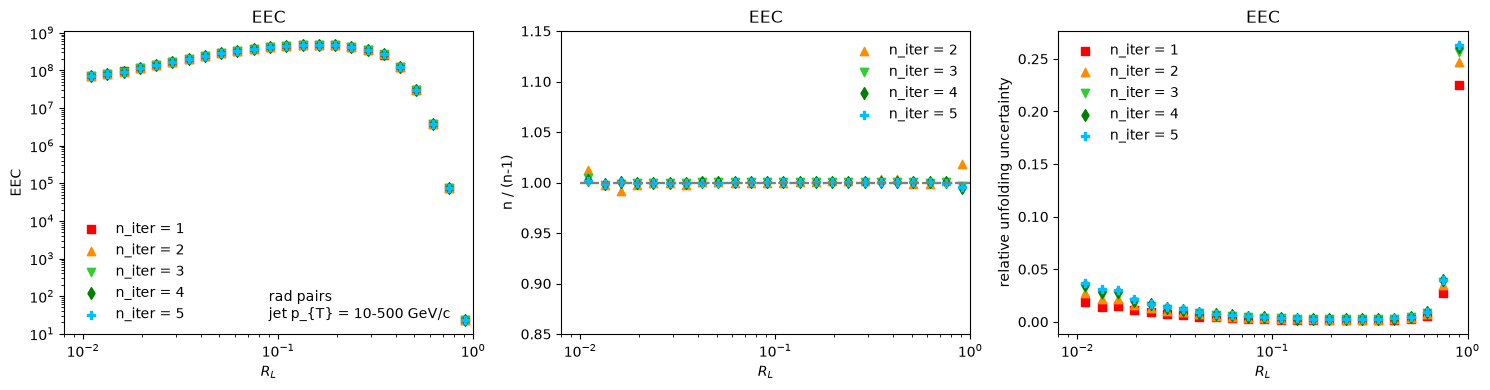

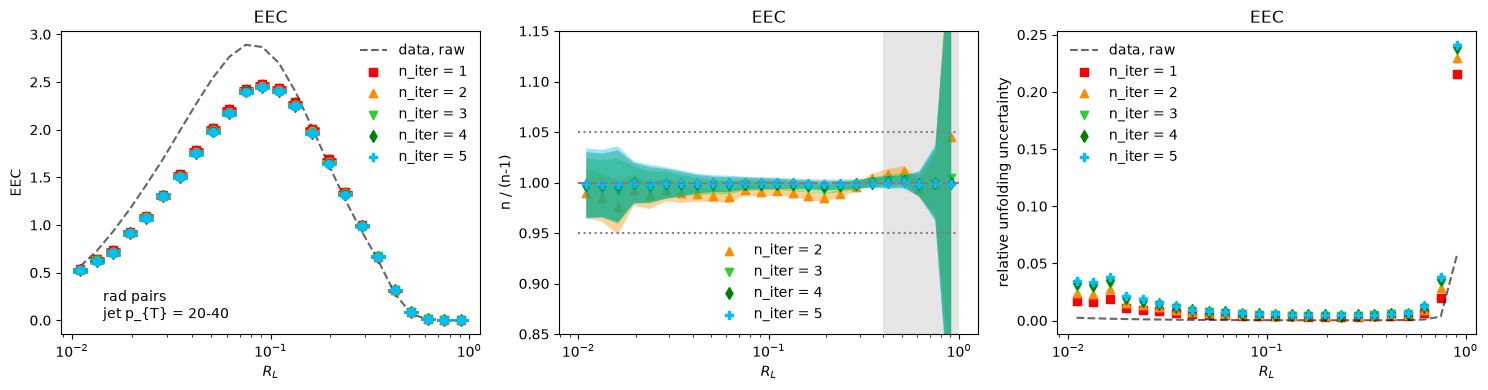

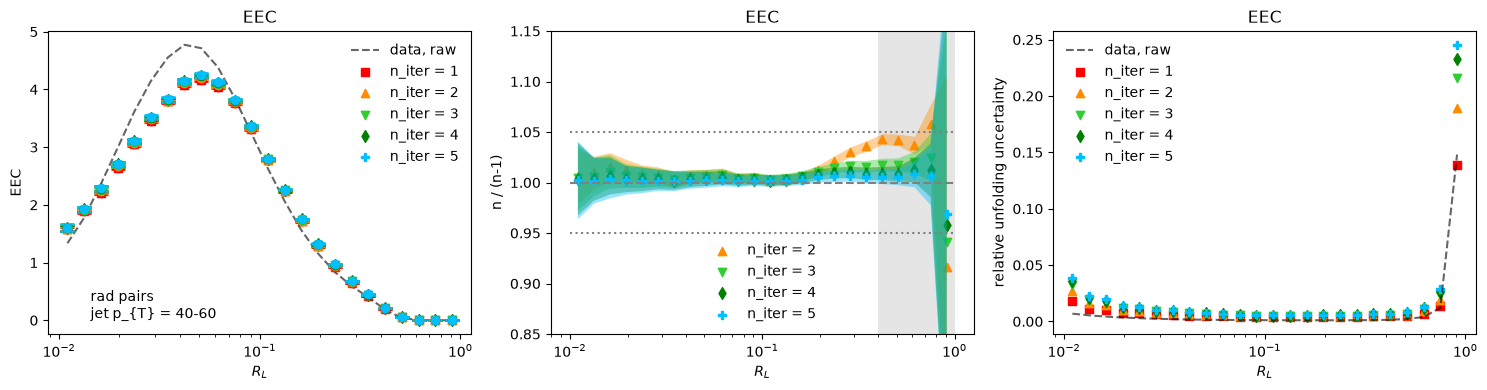

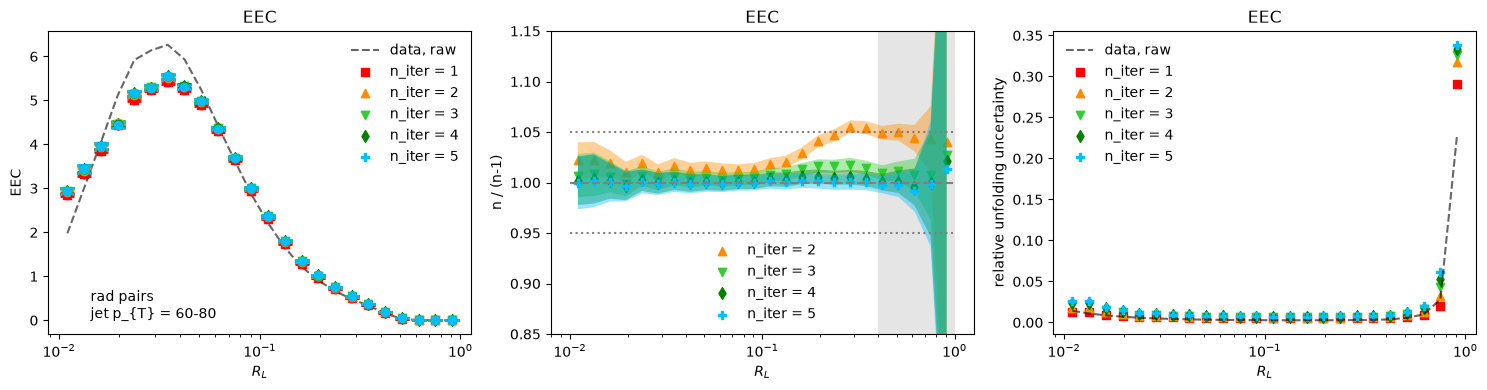

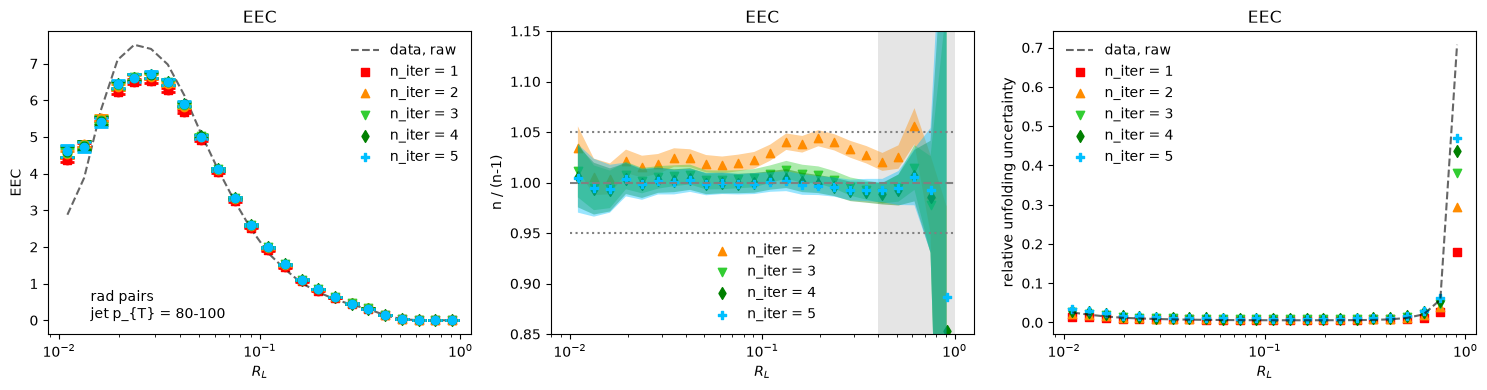

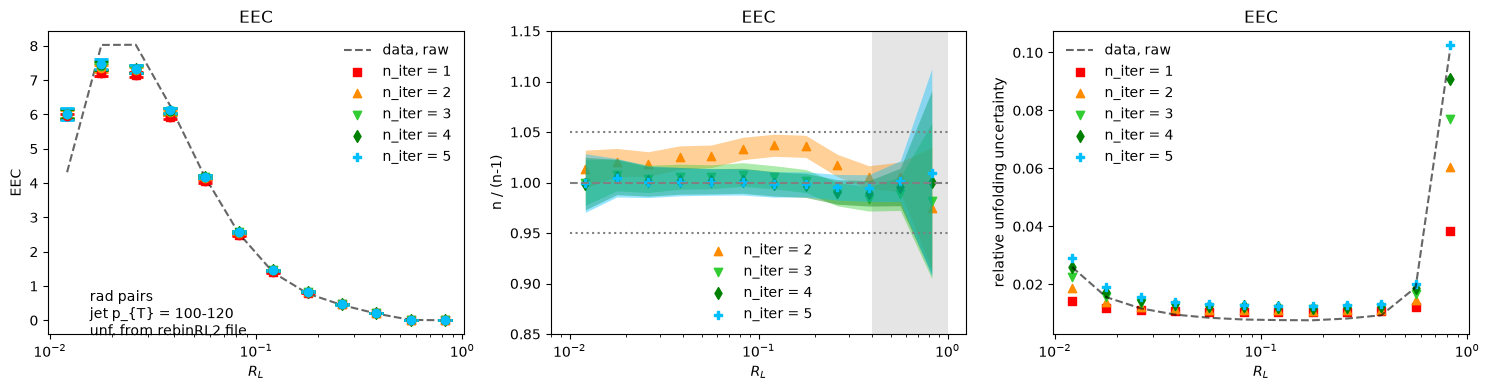

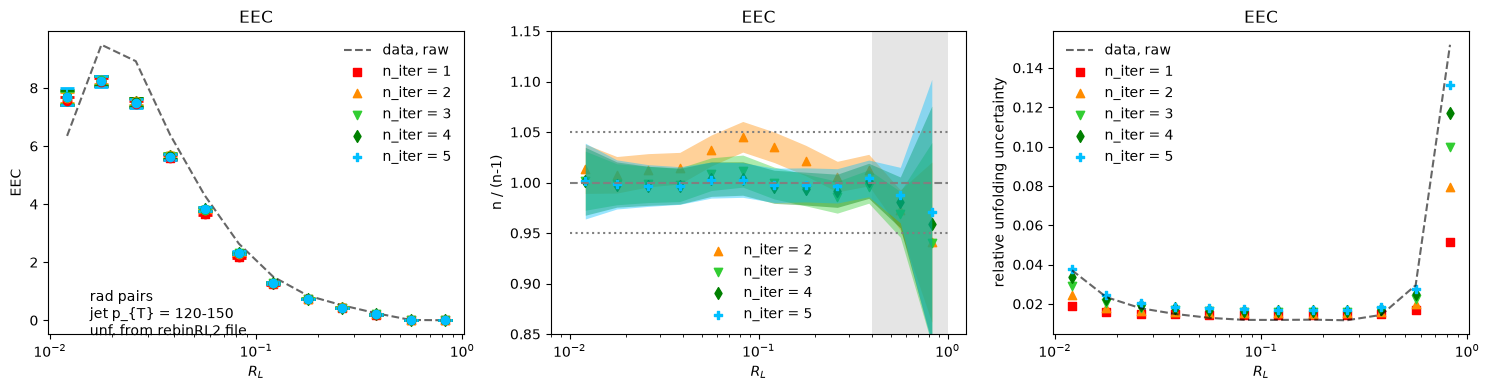

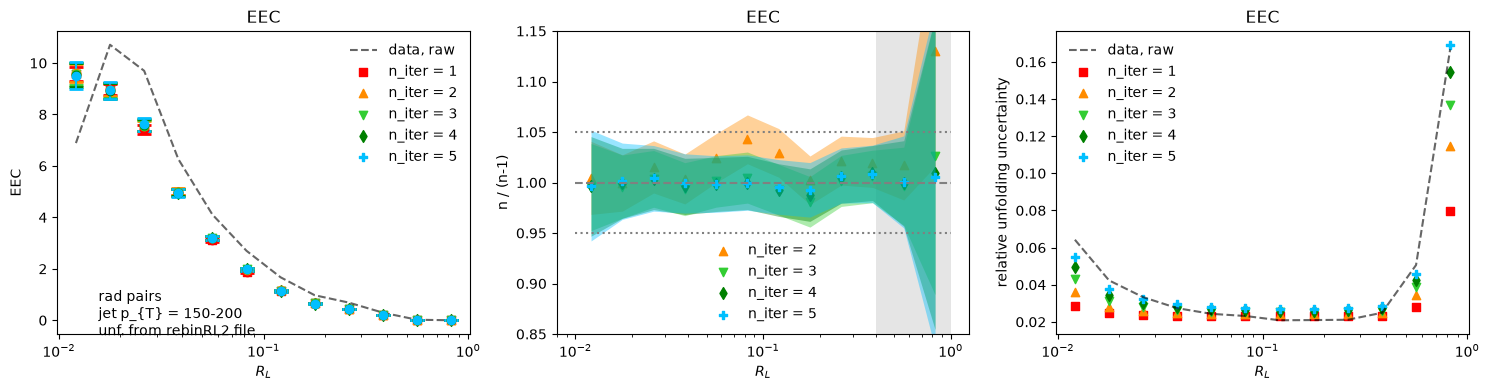

In [20]:
lab = "rad"
h3_raw, h1_raw, h3_reco, h1_reco, h3_gen, h1_gen, h3_unfolded, h3_raw_purity = get_histograms(lab, f_unfolded, f_preunfold_data, f_preunfold_rm) #, f_prefundold_gen)
matrix1D, matricies = get_matrices(lab, f_unfolded, f_unfolded1D, n_bins, n_bins_true)
print_response_matricies(matrix1D, matricies, binning_reco, binning, labels)

theta0_G, theta0_S, theta_unknown_S, theta_unfolded, theta0_G_err, theta0_S_err, theta_unknown_S_err, theta_unfolded_err, U_unfolded, U_unfolded_err = get_projections(h3_gen, h3_reco, h3_raw, h3_unfolded)
plot_unfolded_axes_dist(lab, bincenters, theta_unfolded, theta_unfolded_err, L_colors, L_markers, labels, binning,
                        theta0_G, theta0_S, theta_unknown_S, theta0_G_err, theta0_S_err, theta_unknown_S_err)
plot_unfolded_EEC_dist(lab, bincenters, U_unfolded, U_unfolded_err, theta_unfolded, binwidths, L_colors, L_markers, labels, binning)

plot_unfolded_final_EEC_dist(lab, h3_unfolded, bincenters, binwidths, binning, theta_unfolded, N_jets_unf, N_jets_unf_err, h3_raw, N_jets_raw, L_colors, L_markers, labels,
                             h3_unfolded_rebin=h3_unfolded_rebinRL2[lab], rl_rebin_binning=rl_rebin_binning)


## Plot final distribution

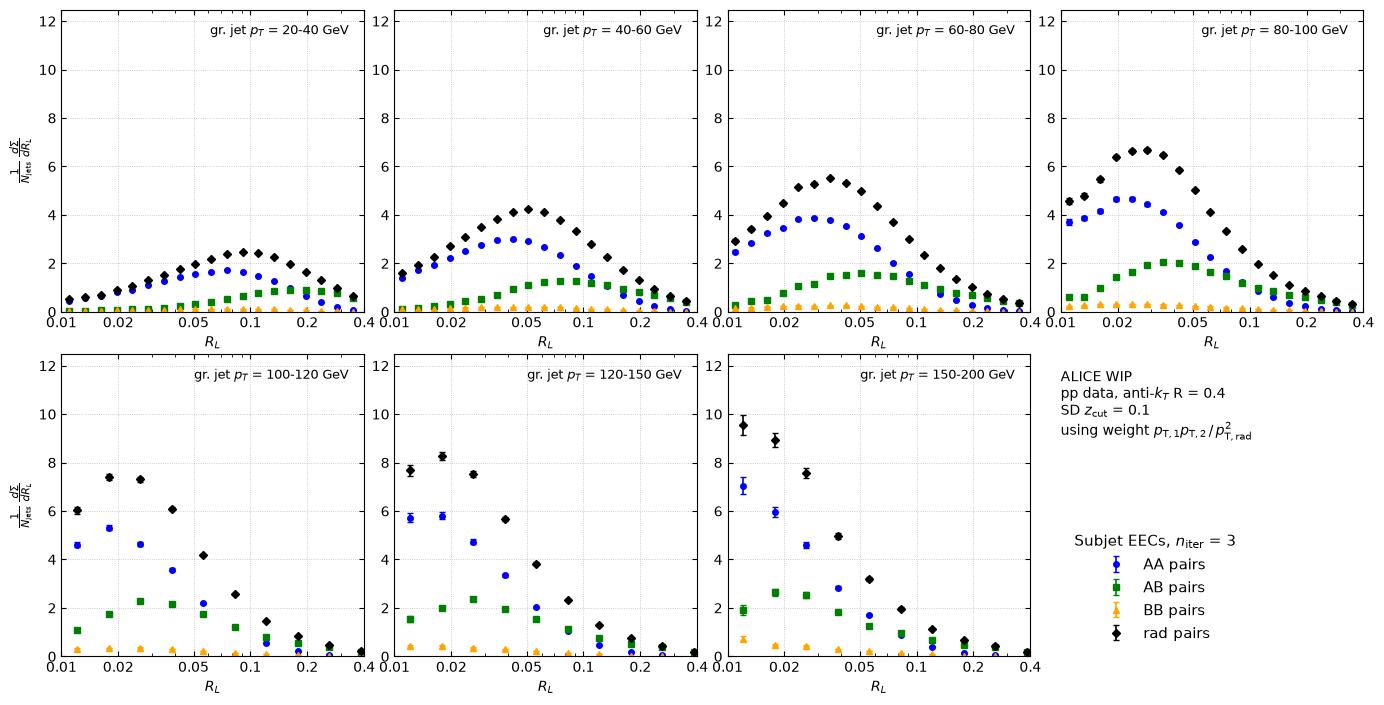

In [24]:
############################## FINAL EEC, ALL PAIR CATEGORIES ##############################
# (1/N_jets) dSigma/dR_L per jet-pT panel, AA/AB/BB/rad superimposed.
# Extraction + normalization follow plot_unfolded_final_EEC_dist above:
#   - Bayesian_Unfolded_{lab}_iter{n} (unfolded.root); RL-rebinned file (12 R_L bins)
#     for pT bins with lower edge >= 100 GeV,
#   - EEC = (U @ w) / dRL / N_jets, N_jets from Baysian_Unfolded1Diter{n}
#     with sqrt(counts) added to its error, propagated via get_ratio_err.
# Layout: shared linear y bounds, tight panel spacing, dotted grid lines,
#         only R_L <= 0.4 shown, pT label per panel,
#         caption (ALICE WIP / sample / weight) above the legend in the last slot.
from matplotlib.ticker import FixedLocator, NullFormatter, FuncFormatter
from jupyter_utils import xslice_th3d, get_ratio_err

BASE_UNF = "/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/"

JETPT_BINS = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500], dtype=np.float64)
RL_BINS = np.logspace(np.log10(0.01), np.log10(1.0), 25)
W_BINS = np.logspace(-5, -0.5, 21)
W_CENTERS = np.sqrt(W_BINS[:-1] * W_BINS[1:])

# RL axis rebinned 24 -> 12 (pairs of adjacent bins merged), as in plots_fr.ipynb
RL_BINS_REBIN2 = RL_BINS[::2]
RL_CENTERS_REBIN2 = np.sqrt(RL_BINS_REBIN2[:-1] * RL_BINS_REBIN2[1:])
RL_WIDTHS_REBIN2 = np.diff(RL_BINS_REBIN2)

RL_BINS_FINE = RL_BINS
RL_CENTERS_FINE = np.sqrt(RL_BINS[:-1] * RL_BINS[1:])
RL_WIDTHS_FINE = np.diff(RL_BINS)

RL_PLOT_MAX = 0.4   # only show points up to this R_L

# pair categories and their plot style (AA blue, BB orange, AB green, rad black)
LAB_STYLE = {
    "AA":  dict(color="blue",    marker="o"),
    "AB":  dict(color="green",   marker="s"),
    "BB":  dict(color="orange",  marker="^"),
    "rad": dict(color="black",   marker="D"),
}
LABELS = list(LAB_STYLE)


def plot_final_EEC_ptpanels(chosen_iter=3, pt_bin_indices=range(1, 8),
                            rebin_pt_threshold=100.0, nrows=2, ncols=4,
                            ax_text_pos=(0.95, 0.95)):
    """
    Final unfolded EEC, normalized as (1/N_jets) dSigma/dR_L, one panel per jet-pT
    bin with all four pair categories (AA, AB, BB, rad) superimposed.

    Extraction and normalization follow plots_fr.ipynb (plot_unfolded_final_EEC_dist):
      - unfolded 3D hists  Bayesian_Unfolded_{lab}_iter{n}  from unfolded.root;
        for pT bins whose lower edge is >= rebin_pt_threshold the RL-rebinned
        unfolding output (unfolded_rebinRL2.root, 12 R_L bins) is used instead,
      - EEC(R_L) = sum_w [ U(R_L, w) * w ] / (N_jets * dR_L),
      - N_jets from the unfolded 1D jet-pT spectrum Baysian_Unfolded1Diter{n}
        (unfolded1D.root), with the sqrt(counts) Poisson term added to its
        uncertainty and the N_jets error propagated onto the EEC.

    Layout: shared linear y bounds across all panels; only points with
    R_L <= RL_PLOT_MAX are shown; each panel carries only its pT label; the last
    grid slot holds the caption (ALICE WIP / sample / weight) above the legend.

    chosen_iter : 1-based unfolding iteration number to draw.
    pt_bin_indices : 0-based indices into JETPT_BINS (default: bins 1-7,
        i.e. 20-40 ... 150-200 GeV, as in plots_fr.ipynb).
    Returns the figure.
    """
    f_unfolded     = ur.open(BASE_UNF + "unfolded.root")
    f_unfolded_reb = ur.open(BASE_UNF + "unfolded_rebinRL2.root")
    f_unfolded1D   = ur.open(BASE_UNF + "unfolded1D.root")

    # N_jets for the chosen iteration: 1D unfolded jet-pT spectrum (9 bins = JETPT_BINS)
    h1_unf = f_unfolded1D[f"Baysian_Unfolded1Diter{chosen_iter}"]
    v1 = np.asarray(h1_unf.values(), dtype=float)
    e1 = np.asarray(h1_unf.errors(), dtype=float)
    assert len(v1) == len(JETPT_BINS) - 1, "1D unfolded jet-pT binning does not match JETPT_BINS"
    N_jets     = v1                                   # one entry per pT bin
    N_jets_err = np.sqrt(e1**2 + v1)                  # proj_err_unf convention (plots_fr.ipynb)

    # unfolded 3D hists for the chosen iteration, per label (fine + RL-rebinned)
    h3_unf      = {lab: f_unfolded[f"Bayesian_Unfolded_{lab}_iter{chosen_iter}"] for lab in LABELS}
    h3_unf_reb  = {lab: f_unfolded_reb[f"Bayesian_Unfolded_{lab}_iter{chosen_iter}"] for lab in LABELS}

    # ---------------- extract all panels first (needed for shared y bounds) ----------------
    pt_bin_indices = list(pt_bin_indices)
    if len(pt_bin_indices) > nrows * ncols - 1:
        raise ValueError("too many pT panels for the grid (last slot holds the legend)")

    data = {}   # (i, lab) -> (rl_centers_shown, eec_shown, eec_err_shown)
    for i in pt_bin_indices:
        for lab in LABELS:
            # unfolded source for this panel: RL-rebinned file for high pT, fine otherwise
            if JETPT_BINS[i] >= rebin_pt_threshold:
                U     = xslice_th3d(h3_unf_reb[lab].values(), i, i + 1)
                U_err = xslice_th3d(h3_unf_reb[lab].errors(), i, i + 1)
                rl_centers, rl_widths = RL_CENTERS_REBIN2, RL_WIDTHS_REBIN2
            else:
                U     = xslice_th3d(h3_unf[lab].values(), i, i + 1)
                U_err = xslice_th3d(h3_unf[lab].errors(), i, i + 1)
                rl_centers, rl_widths = RL_CENTERS_FINE, RL_WIDTHS_FINE

            # EEC = (U @ w) / dRL, error = sqrt(U_err^2 @ w^2) / dRL  (plots_fr.ipynb)
            eec     = np.dot(U, W_CENTERS) / rl_widths
            eec_err = np.sqrt(np.dot(np.asarray(U_err)**2, W_CENTERS**2)) / rl_widths

            # divide by N_jets and propagate its uncertainty
            eec_err = get_ratio_err(eec, N_jets[i], eec_err, N_jets_err[i])
            eec = eec / N_jets[i]

            # only show points up to RL_PLOT_MAX
            show = rl_centers <= RL_PLOT_MAX
            data[(i, lab)] = (rl_centers[show], eec[show], eec_err[show])

    # shared y bounds across all panels
    y_max = max(np.max(e + err) for (_, lab), (_, e, err) in data.items() if len(e))
    y_top = 1.25 * y_max   # headroom for the pT labels

    # ---------------- figure ----------------
    fig = plt.figure(figsize=(4.2 * ncols, 4.2 * nrows))
    gs = fig.add_gridspec(nrows, ncols, hspace=0.14, wspace=0.10)

    handles, names = [], []
    for k, i in enumerate(pt_bin_indices):
        row, col = divmod(k, ncols)
        ax = fig.add_subplot(gs[row, col])

        for lab in LABELS:
            rl_c, eec, eec_err = data[(i, lab)]
            st = LAB_STYLE[lab]
            h = ax.errorbar(rl_c, eec, yerr=eec_err,
                            color=st["color"], marker=st["marker"], ms=4,
                            capsize=2, capthick=1, lw=1.2, linestyle="None",
                            label=f"{lab} pairs")
            if k == 0:
                handles.append(h); names.append(f"{lab} pairs")

        ax.set_xscale("log")
        ax.set_xlim(RL_BINS_FINE[0], RL_PLOT_MAX)
        ax.set_ylim(0, y_top)          # same bounds in every panel
        ax.tick_params(direction="in", which="both", top=True, right=True)
        ax.grid(True, which="major", axis="both", linestyle=":", linewidth=0.6,
                color="gray", alpha=0.5)
        ax.set_xlabel(r"$R_{L}$", fontsize=10)
        if col == 0:
            ax.set_ylabel(r"$\frac{1}{N_{\mathrm{jets}}} \, \frac{d\Sigma}{dR_{L}}$", fontsize=11)

        # clean log ticks over the shortened R_L range
        ax.xaxis.set_major_locator(FixedLocator([0.01, 0.02, 0.05, 0.1, 0.2, 0.4]))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_formatter(NullFormatter())

        # only the pT label on each individual panel
        ax.text(*ax_text_pos, f"gr. jet $p_T$ = {int(JETPT_BINS[i])}-{int(JETPT_BINS[i+1])} GeV",
                transform=ax.transAxes, fontsize=9,
                verticalalignment="top", horizontalalignment="right")

    # last grid slot: caption above the legend
    ax_leg = fig.add_subplot(gs[(nrows - 1), (ncols - 1)])
    ax_leg.axis("off")
    ax_leg.text(0.0, 0.95,
                "ALICE WIP\n"
                "pp data, anti-$k_{T}$ R = 0.4\n"
                r"SD $z_{\mathrm{cut}}$ = 0.1" "\n"
                r"using weight $p_{\mathrm{T,1}} p_{\mathrm{T,2}} \,/\, p_{\mathrm{T,rad}}^{2}$",
                transform=ax_leg.transAxes, fontsize=10, verticalalignment="top")
    ax_leg.legend(handles, names, frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.45),
                  fontsize=11,
                  title=rf"Subjet EECs, $n_{{\mathrm{{iter}}}}$ = {chosen_iter}",
                  title_fontsize=11)

    return fig

# e.g. iteration 3:
fig = plot_final_EEC_ptpanels(chosen_iter=3)


## Other

In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
# individual distros

for iteration in range(1):
    fig, axes = plt.subplots(2, 3, figsize=(15,8))

    # ROW 1: raw distributions
    for i in range(3):
        ax = axes[0, i]

        _,_,_=ax.hist(binning_reco[i][:-1], binning_reco[i], weights=theta0_S[i],color='blue', histtype="step", alpha=1, label="MC, reco")
        print(theta0_S[i])
        _,_,_=ax.hist(binning_reco[i][:-1], binning_reco[i], weights=theta_unknown_S[i],color='orange',histtype="step",linestyle='--',alpha=1,label="Data, reco")

        _,_,_=ax.hist(binning[i][:-1], binning[i], weights=theta0_G[i],color='blue', alpha=0.5, label="MC, true")
        _,_,_=ax.hist(binning[i][:-1], binning[i], weights=theta_unknown_G[i],color='orange',alpha=0.5,label="Data, true")
        _,_,_=ax.hist(binning[i][:-1], binning[i],weights=theta_unfolded[iteration][i],color='black',histtype="step",label="RooUnfolded",lw=1)

        ax.errorbar(bincenters[i], theta0_G[i], yerr=theta0_G_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='blue')
        ax.errorbar(bincenters[i], theta_unknown_G[i], yerr=theta_unknown_G_err[i], capsize=5, capthick=2, fmt='o', linestyle="None", color='orange')
        ax.errorbar(bincenters[i], theta_unfolded[iteration][i], yerr=theta_unfolded_err[iteration][i], capsize=5, capthick=2, fmt='o', linestyle="None", color='black')
        
        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("Counts")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
            ax.set_yscale('log')
            #ax.set_ylim([0.1, 4E8])
    
    # ROW 2: residual plots
    for i in range(3):
        ax = axes[1, i]
        
        yvals, yerrs = get_ratio_safe(theta_unfolded[iteration][i], theta_unknown_G[i], \
                                      numerr=theta_unfolded_err[iteration][i], denomerr=theta_unknown_G_err[i])
        
        ax.step(binning[i], np.insert(yvals, 0, yvals[0]), where="pre",color='red',label="RooUnfolded / true",lw=1)
        ax.errorbar(bincenters[i], yvals, yerr=yerrs, capsize=5, capthick=2, fmt='o', linestyle="None", color='red')

        ax.hlines(y=1, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_xlabel(labels[i])
        ax.set_ylabel("relative error")
        ax.legend(frameon=False)
        
        if i in [0, 1]:
            ax.set_xscale('log')
            ax.set_ylim([0.9, 1.1])
        else:
            ax.set_ylim([0.9, 1.1])

    
    fig.tight_layout()
    # fig.savefig("post_training_" + str(iteration) + ".png")
    # fig.show()
    # plt.close()
plt.show()

In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
# individual distros

it = 3

fig, axes = plt.subplots(4, 3, figsize=(16,16))

# ROW 1: raw distributions
for i in range(3):
    ax = axes[0, i]

    if i == 0:
        ax.plot(bincenters[i][:-1], theta_unknown_G[i][:-1], color='black',label="MC true")
    else:
        ax.plot(bincenters[i], theta_unknown_G[i], color='black',label="MC true")

    for iteration in range(it):
        ax.scatter(bincenters[i], theta_unfolded[iteration][i],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("Counts")

        #ax.errorbar(bincenters[i], theta_unfolded[iteration][i], yerr=theta_unfolded_err[iteration][i], capsize=5, capthick=2, fmt='o', linestyle="None", color=L_colors[iteration])
        
        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_yscale('log')
            #ax.set_ylim([0.1, 4E8])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])

# ROW 2: error wrt Data, true
for i in range(3):
    ax = axes[1, i]

    for iteration in range(1,it):

        yvals, yerrs = get_ratio_safe(theta_unfolded[iteration][i], theta_unknown_G[i], \
                                      numerr=theta_unfolded_err[iteration][i], denomerr=theta_unknown_G_err[i])
        yvals = yvals - 1

        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        if i == 0:
            ax.fill_between(bincenters[i][:-1], (yvals-yerrs)[:-1], (yvals+yerrs)[:-1], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        else:
            ax.fill_between(bincenters[i], yvals-yerrs, yvals+yerrs, alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)

        ax.hlines(y=0, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("EEC relative error wrt Data, true")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_ylim([-0.2, 0.2])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


# ROW 3: convergence plot (n / n - 1)
for i in range(3):
    ax = axes[2, i]

    for iteration in range(1,it):
    
        yvals = safe_divide(theta_unfolded[iteration][i] , theta_unfolded[iteration-1][i], filler=1)
        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[i][0], xmax=binning[i][len(binning[i])-1], color='grey', linestyle='--')

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_ylim([0.9, 1.1])
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


# ROW 4: statistical error %
for i in range(3):
    ax = axes[3, i]

    for iteration in range(it):
        
        yvals = safe_divide(theta_unfolded_err[iteration][i], theta_unfolded[iteration][i])
        ax.scatter(bincenters[i], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title(labels[i])
        ax.set_xlabel(labels[i])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)

        if i in [0, 1]:
            ax.set_xscale('log')
        ax.set_xlim([binning[i][0], binning[i][len(binning[i])-1]])


fig.tight_layout()
plt.show()

In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros

it = 3

fig, axes = plt.subplots(2, 3, figsize=(15,8))

# EEC weight calculation:
# w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true])
#true_EEC_err = np.array([np.dot(col, bincenters[0]) for col in U_true_err])

unfolded_EEC = np.array([[np.dot(col, bincenters[0]) for col in U_unfolded[iteration]] for iteration in range(len(theta_unfolded))])
unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err[iteration]] for iteration in range(len(theta_unfolded))])

# COL 1: raw EEC distribution WITH relative error over data, true underneath
ax = axes[0, 0]

rl_lims = ax.set_xlim([binning[1][0], binning[1][len(binning[1])-1]])

ax.plot(bincenters[1], true_EEC, color='black',label="Data, true")

for iteration in range(it):

    ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
    ax.set_ylabel("EEC")
    
    ax.set_title("EEC")
    ax.set_xlabel(labels[1])

    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(rl_lims)

# row below with the error

ax = axes[1, 0]

ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

for iteration in range(it):

    yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                      numerr=unfolded_EEC_err[iteration], denomerr=np.zeros_like(unfolded_EEC[iteration]), filler=1)
    yvals = yvals - 1

    ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')
    

    ax.set_title("relative error")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("EEC relative error wrt Data, true")

    ax.set_xscale('log')
    ax.set_ylim([-0.5, 0.5])
    ax.set_xlim(rl_lims)


# COL 2: convergence plot (n / n - 1)
ax = axes[0, 1]

for iteration in range(1,it):

    yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
    ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

    ax.set_title("EEC")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("n / (n-1)")
    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_ylim([0.85, 1.15])
    ax.set_xlim(rl_lims)


# COL 3: statistical error %
ax = axes[0, 2]

for iteration in range(it):
    
    yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
    ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

    ax.set_title("EEC")
    ax.set_xlabel(labels[1])
    ax.set_ylabel("unfolding uncertainty %")
    ax.legend(frameon=False)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(rl_lims)


fig.tight_layout()
plt.show()


In [ ]:
################# WENQINGS MC RECO/TRUE RATIOS #################

f_compare = ur.open("./pythiaMC_corr_hists.root")

pythia_names = ["Ratio_hJetE2C_norm_ch_jetR4_2040_trk10", "Ratio_hJetE2C_norm_ch_jetR4_4060_trk10", "Ratio_hJetE2C_norm_ch_jetR4_6080_trk10"]
h1_EEC_ratios = [f_compare[name].values() for name in pythia_names]

print(h1_EEC_ratios)

R_bins_compare = f_compare["Ratio_hJetE2C_norm_ch_jetR4_2040_trk10"].axis("x").edges()
R_bincenters_compare = get_log_bincenters(R_bins_compare)


In [ ]:
N_jets_unf = [7.91905502e+04, 4.07895819e+03, 5.64378641e+02]
N_jets_unf_err = [3.07052137e+02, 6.42184893e+01, 2.37848329e+01]
N_jets_true = [7.92135529e+04, 4.07969140e+03, 5.64283433e+02]
N_jets_raw = [5.46348066e+04, 2.53230942e+03, 3.17720949e+02]

In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
############################## ( with pT cut applied ) ###########################

# EEC distros

it = 3

j = 0
for i in range(2, 5):

    fig, axes = plt.subplots(1, 4, figsize=(20,4))

    ptcut_bins = [i, i+1]
    slice_on_pt = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    ptcut_bins_reco = [i-1, i]
    slice_on_pt_reco = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    U_true_cut = slice_on_pt(h3_true.values()) #  * h3_purity.values())
    U_true_err_cut = slice_on_pt(h3_true.errors())

    U_unfolded_cut = [slice_on_pt(A.values()) for A in h3_unfolded]
    U_unfolded_err_cut = [slice_on_pt(A.errors()) for A in h3_unfolded]

    # EEC weight calculation:
    # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

    true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true_cut]) / N_jets_true[j]
    true_EEC_err = np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_true_err_cut]) / N_jets_true[j]

    unfolded_EEC = np.array([[np.dot(col, bincenters[0]) for col in U_unfolded_cut[iteration]] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err_cut[iteration]] for iteration in range(len(theta_unfolded))])

    # divide by number of jets, and propagate error in number of unfolded jets
    unfolded_EEC_err = np.array([get_ratio_err(unfolded_EEC[iteration], N_jets_unf[j], unfolded_EEC_err[iteration], N_jets_unf_err[j]) for iteration in range(len(theta_unfolded))])
    unfolded_EEC /= N_jets_unf[j]

    #unfolded_EEC_err = np.array([[np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err[iteration]] for iteration in range(len(theta_unfolded))]) / N_jets_unf[j]

    # COL 1: raw EEC distribution WITH relative error over data, true underneath
    ax = axes[0]

    rl_lims = ax.set_xlim([binning[1][0], binning[1][len(binning[1])-1]])

    # various comparison EEC plots

    # Data, true, unbinned in energy weight (is the actaul truth)
    # should be close to RM binning when energy weight granulatrity is ok, also used to check definition of energy weight log bin center
    # apply purity correction too
    true_eec_unbinned = yslice(h2_true_eec.values(), ptcut_bins[0], ptcut_bins[1]) / N_jets_true[j]
    true_eec_unbinned_err = yslice(h2_true_eec.errors(), ptcut_bins[0], ptcut_bins[1]) / N_jets_true[j]
    ax.plot(bincenters[1], true_eec_unbinned, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    # Data, raw, unbinned in energy weight
    raw_eec_unbinned = yslice(h2_raw_eec.values(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / N_jets_raw[j]
    raw_eec_unbinned_err = yslice(h2_raw_eec.errors(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / N_jets_raw[j]
    ax.plot(bincenters[1], raw_eec_unbinned, color='red', alpha=0.6, linestyle='dashed', label="Data, raw, unbinned")

    # Data, true, RM binning with binnings from the response matrix (i.e. calculated with some binned energy weight)
    ax.plot(bincenters[1], true_EEC, color='blue', alpha=0.6, label="Data, true, RM binning")

    #print(true_eec_unbinned / raw_eec_unbinned)

    for iteration in range(it):

        ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("EEC")
        
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])

        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    # row below with the error

    ax = axes[1]

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='blue', linestyle='solid')

    # compare with Wenqing's reco / true ratios
    ax.plot(R_bincenters_compare, h1_EEC_ratios[j] - 1, color='green', alpha=0.6, label="Wenqing's MC reco / true")

    yvals, yerrs = get_ratio_safe(true_eec_unbinned, true_EEC, \
                                        numerr=true_EEC_err, denomerr=true_eec_unbinned_err, filler=1)
    yvals = yvals - 1
    #ax.plot(bincenters[1], yvals, color='black',linestyle='dashed', alpha=0.6, label="Data, true, unbinned")

    yvals, yerrs = get_ratio_safe(raw_eec_unbinned, true_EEC, \
                                        numerr=raw_eec_unbinned, denomerr=true_eec_unbinned_err, filler=1)
    yvals = yvals - 1
    ax.plot(bincenters[1], yvals, color='red', alpha=0.6, linestyle='dashed', label="my reco, unbinned / true")

    for iteration in range(it):

        yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                        numerr=unfolded_EEC_err[iteration], denomerr=true_EEC_err, filler=1)
        yvals = yvals - 1

        ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],lw=1)

        ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        
        ax.legend(frameon=False)
        ax.set_title("relative error")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("EEC relative error wrt Data, true, RM binning")

        ax.set_xscale('log')
        ax.set_ylim([-0.3, 0.3])
        ax.set_xlim(rl_lims)


    # COL 2: convergence plot (n / n - 1)
    ax = axes[2]

    for iteration in range(1,it):

        yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("n / (n-1)")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_ylim([0.85, 1.15])
        ax.set_xlim(rl_lims)


    # COL 3: statistical error %
    ax = axes[3]

    for iteration in range(it):
        
        yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title("EEC")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative unfolding uncertainty")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)


    fig.tight_layout()
    plt.show()

    j += 1


In [ ]:
############################## UNFOLDED DISTRIBUTIONS ############################
############################## ( with pT cut applied ) ###########################

# EEC distros

it = 3

fig, axes = plt.subplots(3, 4, figsize=(20,12))

j = 0
for i in range(2, 5):    

    ptcut_bins = [i, i+1]
    slice_on_pt = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    ptcut_bins_reco = [i-1, i]
    slice_on_pt_reco = lambda h : zslice(h, ptcut_bins[0], ptcut_bins[1]).T

    U_true_cut = slice_on_pt(h3_true.values()) #  * h3_purity.values())
    U_true_err_cut = slice_on_pt(h3_true.errors())

    U_unfolded_cut = [slice_on_pt(A.values()) for A in h3_unfolded]
    U_unfolded_err_cut = [slice_on_pt(A.errors()) for A in h3_unfolded]

    ###############################  EEC and error CALCULATION  ###############################
    # EEC weight calculation:
    # w_n = U * b, U is matrixfied RL-energy weight 2D histogram, b is bincenters of energy weights

    true_EEC = np.array([np.dot(col, bincenters[0]) for col in U_true_cut]) / (N_jets_true[j] * binwidths[1])
    true_EEC_err = np.array([np.sqrt(np.dot(col, np.array(bincenters[0])**2)) for col in U_true_err_cut]) / (N_jets_true[j] * binwidths[1])

    unfolded_EEC = np.array([ np.array( [np.dot(col, bincenters[0]) for col in U_unfolded_cut[iteration]] ) / binwidths[1] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.array([np.array([np.sqrt(np.dot(np.array(col)**2, np.array(bincenters[0])**2)) for col in U_unfolded_err_cut[iteration]]) / binwidths[1] for iteration in range(len(theta_unfolded))])

    # add on statistical uncertainty, sum in quadrature
    stat_err = np.array([ np.array( [np.sqrt(np.dot(col, np.array(bincenters[0])**2)) for col in U_unfolded_cut[iteration]] ) / binwidths[1] for iteration in range(len(theta_unfolded))])
    unfolded_EEC_err = np.sqrt(unfolded_EEC_err**2 + stat_err**2)

    # divide by number of jets, and propagate error in number of unfolded jets
    unfolded_EEC_err = np.array([get_ratio_err(unfolded_EEC[iteration], N_jets_unf[j], unfolded_EEC_err[iteration], N_jets_unf_err[j]) for iteration in range(len(theta_unfolded))])
    unfolded_EEC /= N_jets_unf[j]

    ##################################

    # COL 1: raw EEC distribution WITH relative error over data, true underneath
    ax = axes[j, 0]

    rl_lims = ax.set_xlim([1E-2, 1])

    # various comparison EEC plots

    # Data, true, unbinned in energy weight (is the actaul truth)
    # should be close to RM binning when energy weight granulatrity is ok, also used to check definition of energy weight log bin center
    # apply purity correction too
    true_eec_unbinned = yslice(h2_true_eec.values(), ptcut_bins[0], ptcut_bins[1]) / (N_jets_true[j] * binwidths[1])
    true_eec_unbinned_err = yslice(h2_true_eec.errors(), ptcut_bins[0], ptcut_bins[1]) / (N_jets_true[j] * binwidths[1])
    ax.plot(bincenters[1], true_eec_unbinned, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    # Data, raw, unbinned in energy weight
    raw_eec_unbinned = yslice(h2_raw_eec.values(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / (N_jets_raw[j] * binwidths[1])
    raw_eec_unbinned_err = yslice(h2_raw_eec.errors(), ptcut_bins_reco[0], ptcut_bins_reco[1]) / (N_jets_raw[j] * binwidths[1])
    ax.plot(bincenters[1], raw_eec_unbinned, color='red', alpha=0.6, linestyle='dashed', label="Data, reco, unbinned")

    # Data, true, RM binning with binnings from the response matrix (i.e. calculated with some binned energy weight)
    ax.plot(bincenters[1], true_EEC, color='blue', alpha=0.6, label="Data, true, RM binning")

    #print(true_eec_unbinned / raw_eec_unbinned)

    for iteration in range(it):

        ax.scatter(bincenters[1], unfolded_EEC[iteration],color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)
        ax.set_ylabel("$\\frac{1}{N_{jets}}\\frac{d\Sigma}{dR_L}$", fontsize=14)
        
        ax.set_title("EEC")
        ax.set_xlabel(labels[1])

        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    # row below with the error

    ax = axes[j, 1]

    ax.hlines(y=0, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='blue', linestyle='solid')

    yvals, yerrs = get_ratio_safe(true_eec_unbinned, true_EEC, \
                                        numerr=true_eec_unbinned_err, denomerr=true_EEC_err, filler=1)
    yvals = yvals - 1
    ax.plot(bincenters[1], yvals, color='black', alpha=0.6, linestyle='dashed', label="Data, true, unbinned")

    for iteration in range(it):

        yvals, yerrs = get_ratio_safe(unfolded_EEC[iteration], true_EEC, \
                                        numerr=unfolded_EEC_err[iteration], denomerr=true_EEC_err, filler=1)
        yvals = yvals - 1

        ax.scatter(bincenters[1][1:], yvals[1:], color=L_colors[iteration],marker=L_markers[iteration],lw=1, label="n_iter = {}".format(iteration+1))

        ax.fill_between(bincenters[1][1:], (yvals-yerrs)[1:], (yvals+yerrs)[1:], alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)
        
        ax.set_ylabel('$\left(\left.\\frac{1}{N_jets}\\frac{d\Sigma}{dR_L} \middle/ \\frac{1}{N_jets}\\frac{d\Sigma_\\text{true}}{dR_L} \\right.\\right) - 1$', fontsize=14)
        
        ax.set_title("relative difference with data, true, RM binning")
        ax.set_xlabel(labels[1])

        ax.set_xscale('log')
        ax.set_ylim([-0.2, 0.2])
        ax.set_xlim(rl_lims)


    # COL 2: convergence plot (n / n - 1)
    ax = axes[j, 2]

    for iteration in range(1,it):

        yvals = safe_divide(unfolded_EEC[iteration], unfolded_EEC[iteration-1], filler=1)
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.hlines(y=1, xmin=binning[1][0], xmax=binning[1][len(binning[1])-1], color='grey', linestyle='--')

        ax.set_title("relative difference by iteration")
        ax.set_xlabel(labels[1])
        ax.set_ylabel('$\left.\\frac{1}{N_jets}\\frac{d\Sigma_n}{dR_L} \middle/ \\frac{1}{N_jets}\\frac{d\Sigma_{n-1}}{dR_L} \\right.$', fontsize=14)
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_ylim([0.9, 1.1])
        ax.set_xlim(rl_lims)


    # COL 3: statistical error %
    ax = axes[j, 3]

    for iteration in range(it):
        
        yvals = safe_divide(unfolded_EEC_err[iteration], unfolded_EEC[iteration])
        ax.scatter(bincenters[1], yvals, color=L_colors[iteration],marker=L_markers[iteration],label="n_iter = {}".format(iteration+1),lw=1)

        ax.set_title("uncertainty")
        ax.set_xlabel(labels[1])
        ax.set_ylabel("relative uncertainty")
        ax.legend(frameon=False)

        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(rl_lims)

    j += 1

fig.tight_layout()
plt.show()


In [31]:
def getbin(bins, value):
    for i in range(len(bins)-1):
        if bins[i] < value and bins[i+1] > value:
        # binlo = float(np.format_float_positional(bins[i], precision=7, unique=False, fractional=False, trim='k'))
        # binhi = float(np.format_float_positional(bins[i+1], precision=7, unique=False, fractional=False, trim='k'))
        # print(binlo, binhi, value)
        # if binlo <= value and binhi > value:
            return i
    return -1

# print([getbin(R_bins_compare, R_bincenter) for R_bincenter in bincenters[1]])
# print([R_bins_compare[i] for i in [getbin(R_bins_compare, R_bincenter) for R_bincenter in bincenters[1]]])

# h1_EECs_samebinning = [[h1_EECs[ptbin][getbin(R_bincenters_compare, R_bincenter)] for R_bincenter in bincenters[1]] for ptbin in range(len(h1_EECs))]
h1_EECs_samebinning = [[h1_EECs[ptbin][getbin(R_bins_compare[ptbin], R_bincenter)] for R_bincenter in bincenters[1]] for ptbin in range(len(h1_EECs))]
# using R_bins_compare (bin edges) instead of R_bincenters_compare (log bin centers) to decide which data bin to use
h1_EECs_samebinning = np.array(h1_EECs_samebinning)

# h1_EECs_err_samebinning = [[h1_EECs_err[ptbin][getbin(R_bincenters_compare, R_bincenter)] for R_bincenter in bincenters[1]] for ptbin in range(len(h1_EECs))]
h1_EECs_err_samebinning = [[h1_EECs_err[ptbin][getbin(R_bins_compare[ptbin], R_bincenter)] for R_bincenter in bincenters[1]] for ptbin in range(len(h1_EECs))]
h1_EECs_err_samebinning = np.array(h1_EECs_err_samebinning)

# print(h1_EECs_samebinning)
# print(h1_EECs_samebinning.shape)

h1_EECs_err_range = []
for ipt in range(3):
    print(20*(ipt+1), 20*(ipt+2))
    
    h1_EECs_err_range.append([])
    for b in range(len(R_bincenters_compare[ipt])):
        if R_bincenters_compare[ipt][b] > 0.01 and R_bincenters_compare[ipt][b] < 0.4:
            h1_EECs_err_range[ipt].append(h1_EECs_err[ipt][b])
    h1_EECs_err_samebinning_range = []
    for b in range(len(bincenters[1])):
        if bincenters[1][b] > 0.01 and bincenters[1][b] < 0.4:
            h1_EECs_err_samebinning_range.append(h1_EECs_err_samebinning[ipt][b])
    print(h1_EECs_err_range[ipt])
    print(h1_EECs_err_samebinning_range)

20 40
[0.014529287112638593, 0.030593782471729506, 0.015305363522375983, 0.02237437674868906, 0.018806375104320403, 0.016253409723983526, 0.020297503733743547, 0.014366834293923412, 0.016598834218484893, 0.01891640766475601, 0.01924333156919977, 0.014742539812978066, 0.012139719010618359, 0.014923493538961736, 0.015231136437444377, 0.01881832977092891, 0.017463932725941975, 0.020501851062449214, 0.02412187543603487, 0.029566094204674345]
[0.030593782471729506, 0.02237437674868906, 0.016253409723983526, 0.020297503733743547, 0.016598834218484893, 0.01924333156919977, 0.014923493538961736, 0.01881832977092891, 0.020501851062449214, 0.02412187543603487]
40 60
[0.023324770539216905, 0.028824665518444224, 0.025545270523082794, 0.036071904898123536, 0.03713018553672655, 0.03195458607382021, 0.024475235935980687, 0.027529410224216247, 0.02516504949551256, 0.023313483366536096, 0.02152878246036462, 0.02470523195066753, 0.02040921938819421, 0.02403849417430033, 0.022048773268107877, 0.033184151